In [1]:
import pandas as pd 
import numpy as np 
import os 
import matplotlib.pyplot as plt 
import matplotlib.pyplot as plt
from upsetplot import from_contents, plot
import matplotlib
from upsetplot import plot, from_contents # Import from_contents
import pandas as pd 
import os 
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import hdbscan
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
import umap.umap_ as umap
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans

In [2]:
SHH_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\SHH_Alt.csv", index_col=0)
G4_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G4_Alt.csv", index_col=0)
G3_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G3_Alt.csv", index_col=0)
WNT_Alt = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\WNT_Alt.csv", index_col=0)


SHH_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\SHH_Ref.csv", index_col=0)
G4_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G4_Ref.csv", index_col=0)
G3_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\G3_Ref.csv", index_col=0)
WNT_Ref = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\new_filtered_sites_ICGC_only\WNT_Ref.csv", index_col=0)


C:\Users\17867\.conda\envs\my_r_env\Lib\site-packages\upsetplot\data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
C:\Users\17867\.conda\envs\my_r_env\Lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, i

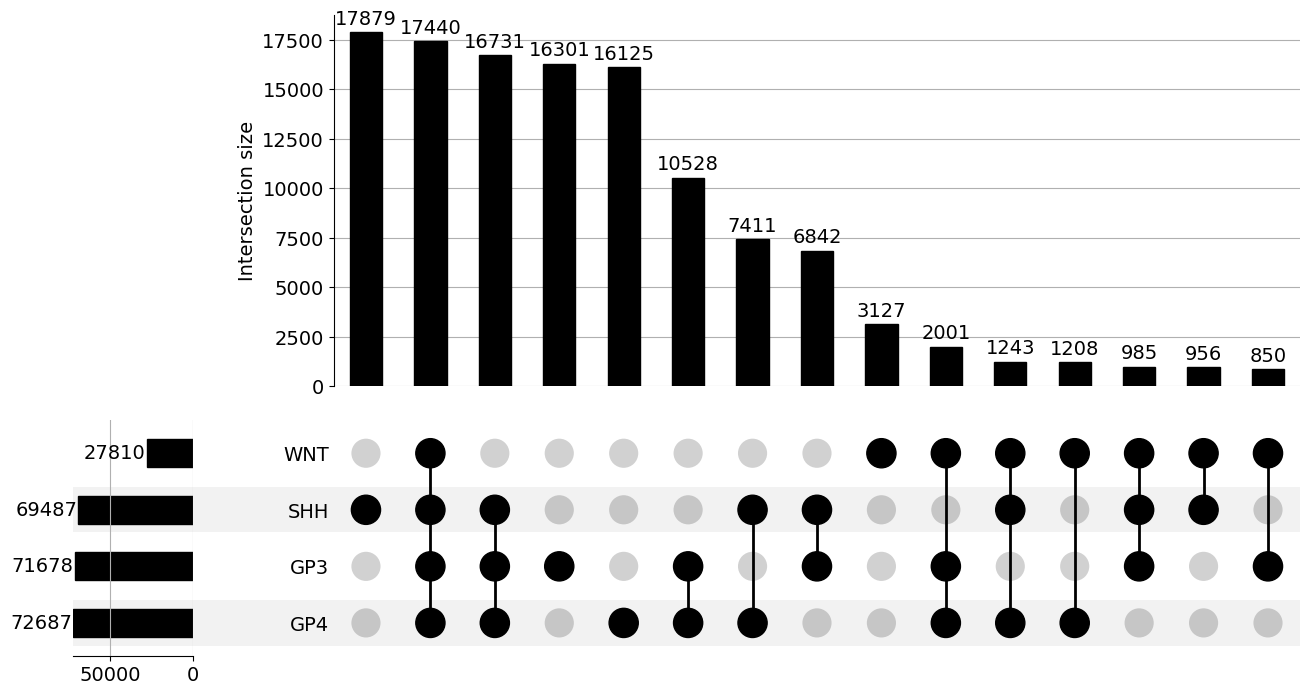

In [3]:
# Alt = pd.DataFrame({'SHH':SHH_Alt.sum(axis=1),'GP3':G3_Alt.sum(axis=1),'GP4':G4_Alt.sum(axis=1),'WNT':WNT_Alt.sum(axis=1)})!=0
# Alt = Alt.T

Alt = pd.DataFrame({'SHH':SHH_Alt.sum(axis=1),'GP3':G3_Alt.sum(axis=1),'GP4':G4_Alt.sum(axis=1),'WNT':WNT_Alt.sum(axis=1)})!=0
Alt = Alt.T


# Optional: increase global font size for better readability
matplotlib.rcParams.update({'font.size': 14})

# Prepare upset_data (assuming you've already run your lambda)
upset_data = from_contents(Alt.apply(lambda x: x.index[x].tolist(), axis=1))

# Create a larger figure and plot
fig = plt.figure(figsize=(18, 10))  # Larger width and height
plot(
    upset_data,
    fig=fig,
    show_counts=True,
    element_size=60,  # Bigger matrix elements (dots/bars)
    sort_by='cardinality',
    sort_categories_by='cardinality'
)

plt.tight_layout()  # Adjust layout to prevent clipping
# plt.savefig(Fig_dir+"/upsetplot.tiff", dpi= 600)
plt.show()


In [4]:
# genome = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end correction\Annovar_analysis/184399_selected_sites_genome_summary.csv") #E:\MB_Bulk_RNA_seq\retest_paired_end_correction\Annovar_analysis
genome = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction\Annovar_analysis/184399_selected_sites_genome_summary.csv") #E:\MB_Bulk_RNA_seq\retest_paired_end_correction\Annovar_analysis

genome.index = genome.Chr +"_"+ genome['Start'].astype(str)
ICGC_genome = genome.loc[Alt.columns]

In [5]:
denovo = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction\sites_public_and_denovo/merged_ICGC_st_Jude_sorted.bed",sep='\t', names=['chr','start','end','gene','.','strand'])
public = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction\sites_public_and_denovo/unique_intervals_RADAR_rediportal_darned_genes_positive_or_negative_strand_unique_sites.bed",sep='\t',names = denovo.columns)

public.head()
public.index = public.chr +"_" + public.start.astype(str)
denovo.index = denovo.chr +"_" + denovo.start.astype(str)


ICGC_genome_denovo = ICGC_genome.loc[~ICGC_genome.index.isin(public.index)]
ICGC_genome_public = ICGC_genome.loc[ICGC_genome.index.isin(public.index)]

print(ICGC_genome_denovo.shape)
print(ICGC_genome_public.shape)


(64588, 115)
(55039, 115)


In [6]:
merge_map = {
    'intron': 'intronic',
    'ncRNA_intronic': 'intronic',

    'ncRNA_exonic': 'exonic',

    'ncRNA_splicing': 'splicing',
    'ncRNA_exonic;splicing': 'splicing',

    'upstream': 'flanking',
    'downstream': 'flanking',
    'upstream;downstream': 'flanking',
}

ICGC_genome_denovo['Func.ensGene'] = (
    ICGC_genome_denovo['Func.ensGene'].replace(merge_map)
)

ICGC_genome_public['Func.ensGene'] = (
    ICGC_genome_public['Func.ensGene'].replace(merge_map)
)

C:\Users\17867\AppData\Local\Temp\ipykernel_22072\4004445979.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ICGC_genome_denovo['Func.ensGene'] = (
C:\Users\17867\AppData\Local\Temp\ipykernel_22072\4004445979.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ICGC_genome_public['Func.ensGene'] = (


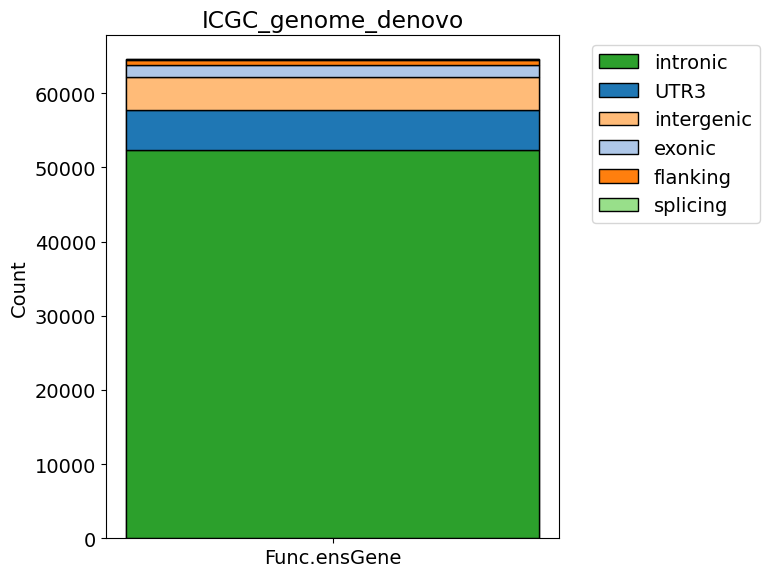

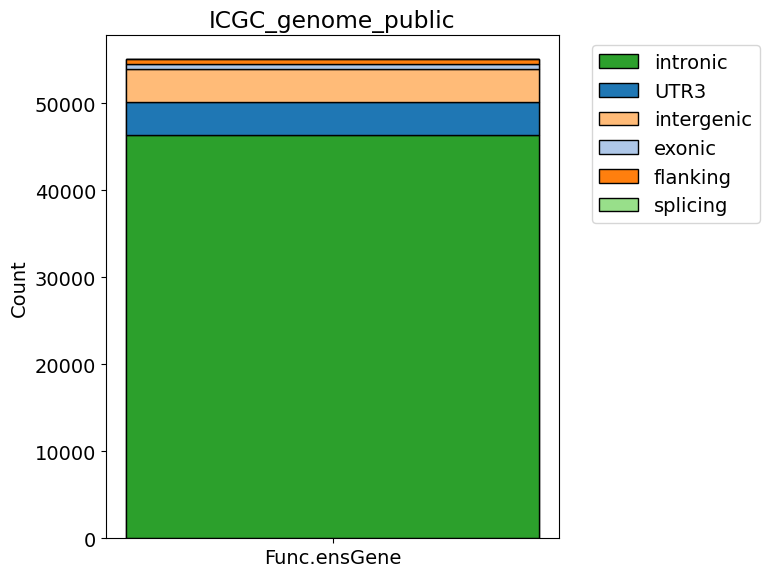

In [7]:
def get_shared_color_map(dfs, column, cmap=plt.cm.tab20):
    """Build one consistent category->color mapping across multiple dataframes."""
    all_categories = set()
    for df in dfs:
        all_categories |= set(df[column].unique())
    all_categories = sorted(all_categories)
    colors = cmap.colors
    return {cat: colors[i % len(colors)] for i, cat in enumerate(all_categories)}

def plot_stacked_bar(df, column, title, color_map):
    counts = df[column].value_counts()

    plt.figure(figsize=(8, 6))
    plt.bar(column, counts.sum(), color='lightgrey', edgecolor='black')

    bottom = 0
    for category, count in counts.items():
        plt.bar(column, count, bottom=bottom,
                color=color_map[category], edgecolor='black', label=category)
        bottom += count

    plt.ylabel('Count')
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# --- Usage ---
color_map = get_shared_color_map(
    [ICGC_genome_denovo, ICGC_genome_public], 'Func.ensGene'
)

plot_stacked_bar(ICGC_genome_denovo, 'Func.ensGene', 'ICGC_genome_denovo', color_map)
plot_stacked_bar(ICGC_genome_public, 'Func.ensGene', 'ICGC_genome_public', color_map)

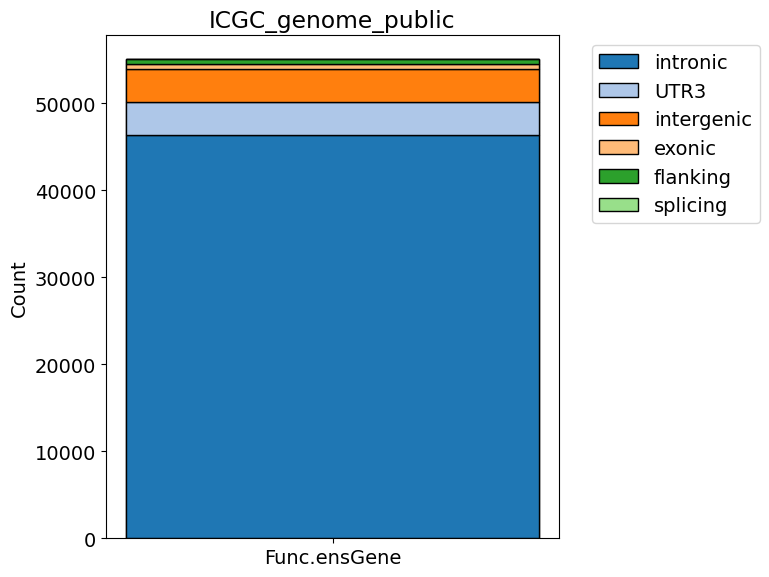

In [8]:
counts = ICGC_genome_public['Func.ensGene'].value_counts()

plt.figure(figsize=(8, 6))
plt.bar('Func.ensGene', counts.sum(), color='lightgrey', edgecolor='black')

# Plot segments on top of the same bar (stacked)
bottom = 0
colors = plt.cm.tab20.colors  # Get a list of colors
for i, (category, count) in enumerate(counts.items()):
    plt.bar('Func.ensGene', count, bottom=bottom, color=colors[i % len(colors)], edgecolor='black', label=category)
    bottom += count

plt.ylabel('Count')
plt.title('ICGC_genome_public')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [17]:
os.listdir(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction")

['A2G_Indexer',
 'Annovar_analysis',
 'bam_files',
 'cibersort_result',
 'Differentially_edited_sites',
 'False_positive_filter',
 'ICGC_gene_count',
 'ICGC_pileup',
 'initial_preparation_for_pileup',
 'mosdepth_output',
 'PCA_Data',
 'pre_depth_filter_all_sites_for_ALU_wannovar_input.txt',
 'rmsk_pre_depth_filter_all_sites_for_ALU_wannovar_input.txt.hg38_rmsk',
 'scripts',
 'scRNA',
 'sites_public_and_denovo',
 'Slides',
 'st_jude_pile_up']

In [18]:
### Alu test
Alu_output = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction/rmsk_pre_depth_filter_all_sites_for_ALU_wannovar_input.txt.hg38_rmsk",sep='\t',
                         names=['rmsk','Name','chr','start','end','ref','alt','strand'])
Alu_status = [name[5:8] for name in Alu_output.Name]
Alu_output['Alu_status'] = Alu_status
Alu_output.loc[Alu_output['Alu_status'] != 'Alu', 'Alu_status'] = 'Non Alu repeats'
Alu_output.index = Alu_output.chr +"_" +Alu_output.start.astype(str)

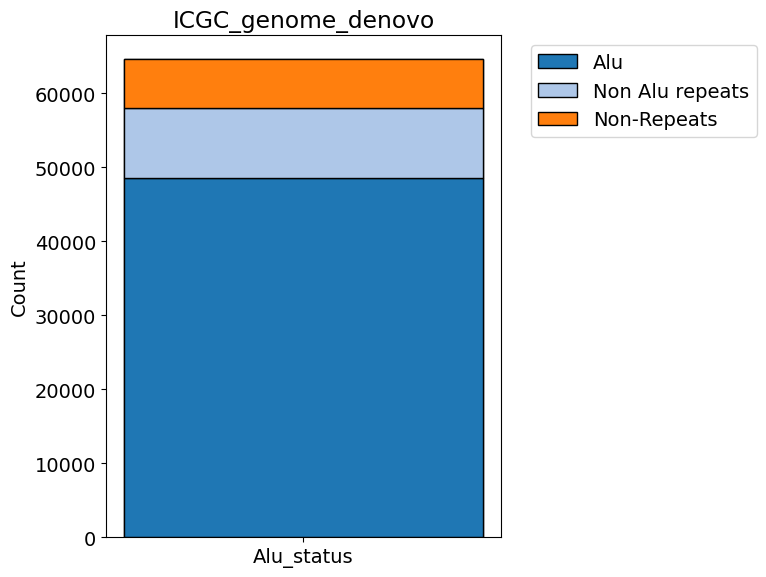

In [19]:
counts = Alu_output.loc[np.intersect1d(Alu_output.index,ICGC_genome_denovo.index)]['Alu_status'].value_counts()
counts['Non-Repeats'] = ICGC_genome_denovo.shape[0]-Alu_output.loc[np.intersect1d(Alu_output.index,ICGC_genome_denovo.index)].shape[0]
plt.figure(figsize=(8, 6))
plt.bar('Alu_status', counts.sum(), color='lightgrey', edgecolor='black')

# Plot segments on top of the same bar (stacked)
bottom = 0
colors = plt.cm.tab20.colors  # Get a list of colors
for i, (category, count) in enumerate(counts.items()):
    plt.bar('Alu_status', count, bottom=bottom, color=colors[i % len(colors)], edgecolor='black', label=category)
    bottom += count

plt.ylabel('Count')
plt.title('ICGC_genome_denovo')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

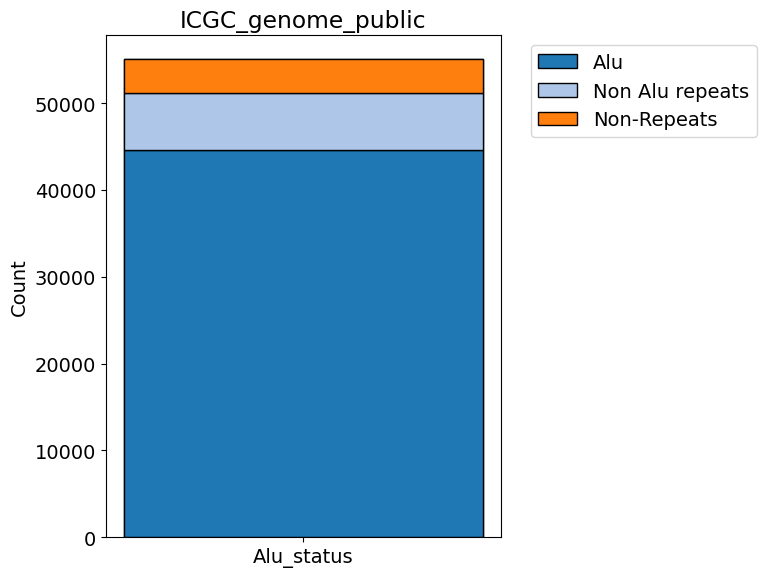

In [20]:
counts = Alu_output.loc[np.intersect1d(Alu_output.index,ICGC_genome_public.index)]['Alu_status'].value_counts()
counts['Non-Repeats'] = ICGC_genome_public.shape[0]-Alu_output.loc[np.intersect1d(Alu_output.index,ICGC_genome_public.index)].shape[0]
plt.figure(figsize=(8, 6))
plt.bar('Alu_status', counts.sum(), color='lightgrey', edgecolor='black')

# Plot segments on top of the same bar (stacked)
bottom = 0
colors = plt.cm.tab20.colors  # Get a list of colors
for i, (category, count) in enumerate(counts.items()):
    plt.bar('Alu_status', count, bottom=bottom, color=colors[i % len(colors)], edgecolor='black', label=category)
    bottom += count

plt.ylabel('Count')
plt.title('ICGC_genome_public')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [21]:
print(len(np.intersect1d(ICGC_genome.index, denovo.index)))
print(len(np.intersect1d(np.intersect1d(ICGC_genome.index, denovo.index),np.intersect1d(ICGC_genome.index, public.index))))
print(len(np.intersect1d(ICGC_genome.index, public.index)))

76212
11624
55039


In [22]:
# ICGC_genome.to_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\genome_information\ICGC_genome_information.csv")

In [23]:
ICGC_genome = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\genome_information\ICGC_genome_information.csv", index_col=0)
ICGC_genome_list = pd.DataFrame(np.unique(ICGC_genome['Gene.ensGene'].str.split(';').explode().str.strip().values), columns=['gene_name'])
# ICGC_genome_list.to_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\genome_information\ICGC_genome_list.csv")

### Clustering and selection of essential sites for subgroup classification

In [28]:
# Reading the metadata for the ICGC and St. Jude data
meta_st_jude = pd.read_csv(r"E:\Medulloblastoma_A_to_I_editing_paper_final_analysis\data\meta_data/ST.JUDE_SAMPLE_INFO.csv")
meta_ICGC = pd.read_csv(r"E:\Medulloblastoma_A_to_I_editing_paper_final_analysis\data\meta_data/exported_meta_filtered_ICGC.csv")
meta_st_jude = meta_st_jude[~meta_st_jude['file_path'].str.endswith('Seq.bam.bai')]
meta_st_jude['sample'] = meta_st_jude['sample_name']+".RNA-Seq_1.fq.gz"
meta_st_jude = meta_st_jude[meta_st_jude['sample']!='SJWLM030910_X1.RNA-Seq_1.fq.gz']
meta_st_jude['sample'] = meta_st_jude['sample_name']+".RNA-Seq_1.fq.gz"

# Define a mapping dictionary for replacement
mapping = {
    'MBLSHH': 'SHH',
    'MBLWNT': 'WNT',
    'MBLG4': 'Group 4',
    'MBLG3': 'Group 3',
    'MBL;MBLG4': 'Group 4',
    'MBLSHH;WT': 'SHH',
    'MBL;MBLSHH': 'SHH',
    'MBL;MBLG3': 'Group 3',
    'AMBLNWSG3;MBLG3': 'Group 3'
}

# Replace using the mapping
meta_st_jude['Subgroup'] = meta_st_jude['sj_associated_diagnoses_disease_code'].replace(mapping)
A2G = pd.read_csv(r"E:\MB_Bulk_RNA_seq\retest_paired_end_correction\False_positive_filter\Bulk_MB_Analysis_Data\Edit_summary.csv", index_col=0)
A2G.index = A2G.index.str.replace(".RNA-Seq_1","")
# freq.columns = freq.columns.str.replace(".RNA-Seq_1.fq.gz","")
# freq_filt = freq_filt.loc[A2G.index]
labels = A2G.subgroup

### Reading the table
MB_Ref = pd.read_csv(r"E:\Medulloblastoma_A_to_I_editing_paper_final_analysis\data\False_positive_filter/Final_Ref_filtered_depth_Alt_freq.csv",index_col =0)
MB_Alt = pd.read_csv(r"E:\Medulloblastoma_A_to_I_editing_paper_final_analysis\data\False_positive_filter/Final_Alt_filtered_depth_Alt_freq.csv", index_col = 0)

freq = MB_Alt/(MB_Alt+MB_Ref)
freq = freq.fillna(0)

freq.columns = freq.columns.str.replace("_Alt","")
freq.columns = freq.columns.str.replace(".RNA-Seq_1.fq.gz","")
freq = freq[A2G.index]

labels = A2G.loc[freq.columns][['subgroup']]

freq = freq.T

In [29]:
freq_ICGC = freq.loc[meta_ICGC.PID]
freq_st_jude = freq.drop(meta_ICGC.PID)
freq_ICGC = freq_ICGC[ICGC_genome.index]

labels = labels[labels.index.str.contains("ICGC")][['subgroup']]
labels = labels.loc[freq_ICGC.index]['subgroup'].values

In [30]:
# Scale features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(freq_ICGC)
selector = SelectKBest(f_classif, k="all")
selector.fit(scaled_features, labels)

scores = selector.scores_

C:\Users\17867\.conda\envs\my_r_env\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [    97    302    449 ... 119205 119336 119586] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\17867\.conda\envs\my_r_env\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [31]:
# 1. Create a DataFrame to pair feature names with scores
feature_names = freq_ICGC.columns
feature_scores = pd.DataFrame({
    'Feature': feature_names,
    'Score': selector.scores_,
    'P-values': selector.pvalues_
})

# 2. Sort by score in descending order
feature_scores = feature_scores.sort_values(by='Score', ascending=False)

# 3. View the top features
print(feature_scores.head(20))

                Feature       Score      P-values
95218     chr6_42889288  194.484145  4.222074e-54
70439     chr2_29030183  193.850034  5.211754e-54
26843    chr16_50577404  146.629196  1.887236e-46
13529    chr12_65058930  144.022211  5.534719e-46
26817    chr16_50576801  138.801978  4.981402e-45
118276    chrX_48577960  127.788607  6.271838e-43
21974    chr15_28807046  127.410924  7.440894e-43
67433    chr2_177627724  122.254687  7.954496e-42
26855    chr16_50580487  118.571744  4.507895e-41
69803    chr2_237382261  112.614298  8.070453e-40
26842    chr16_50577403  104.182925  5.726731e-38
26822    chr16_50576819  101.102741  2.874174e-37
26865    chr16_50623121  101.035789  2.977788e-37
50626    chr1_205467507   96.597166  3.224456e-36
22380    chr15_41299219   96.010661  4.440217e-36
61367    chr21_32001201   94.008001  1.336348e-35
67431    chr2_177627172   92.326600  3.409004e-35
49376    chr1_173864028   91.420305  5.672337e-35
88225     chr5_15713090   89.426420  1.758268e-34


In [32]:
from statsmodels.stats.multitest import multipletests
# bonferroni correction
reject, pvals_corrected, _, _ = multipletests(feature_scores['P-values'], 
                                              alpha=0.05, 
                                              method='bonferroni')

# Add the adjusted p-values back to your DataFrame
feature_scores['Adjusted_P_Value'] = pvals_corrected

# Filter for significant features (Adjusted P < 0.05)
significant_features = feature_scores[feature_scores['Adjusted_P_Value'] < 0.01]

print(f"Original features: {len(feature_scores)}")
print(f"Significant features after bonferroni: {len(significant_features)}")
feature_scores[feature_scores['Adjusted_P_Value']< 0.01]


Original features: 119627
Significant features after bonferroni: 1376


,Feature,Score,P-values,Adjusted_P_Value
95218,chr6_42889288,194.484145,4.222074e-54,5.050740e-49
70439,chr2_29030183,193.850034,5.211754e-54,6.234665e-49
26843,chr16_50577404,146.629196,1.887236e-46,2.257644e-41
13529,chr12_65058930,144.022211,5.534719e-46,6.621018e-41
26817,chr16_50576801,138.801978,4.981402e-45,5.959102e-40
...,...,...,...,...
95836,chr6_7119214,13.288772,8.114155e-08,9.706721e-03
70650,chr2_32309752,13.277217,8.225638e-08,9.840084e-03
98391,chr7_128503552,13.271664,8.279774e-08,9.904845e-03
17782,chr13_99805061,13.271231,8.284002e-08,9.909903e-03


In [36]:
feature_scores.to_csv("H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis/temp/K_test.csv", index=False)

<>:1: SyntaxWarning: invalid escape sequence '\B'
<>:1: SyntaxWarning: invalid escape sequence '\B'
C:\Users\17867\AppData\Local\Temp\ipykernel_22072\1648332495.py:1: SyntaxWarning: invalid escape sequence '\B'
  feature_scores.to_csv("H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis/temp/K_test.csv", index=False)


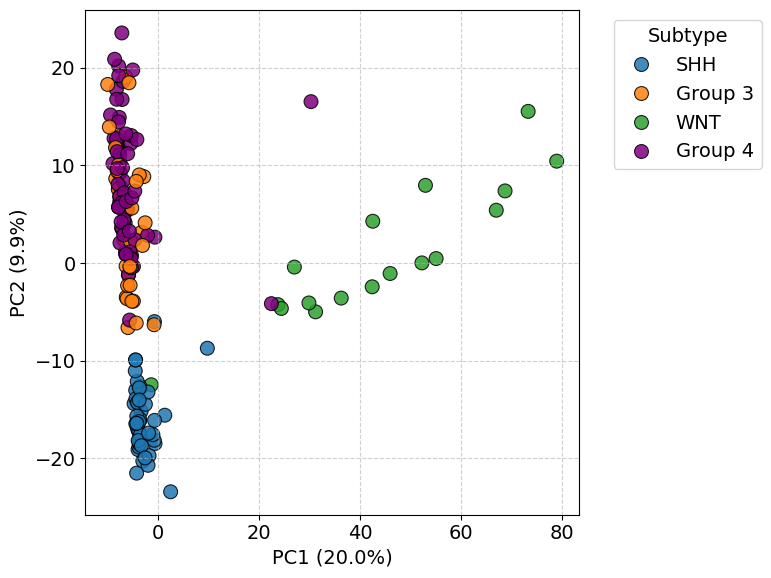

C:\Users\17867\.conda\envs\my_r_env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


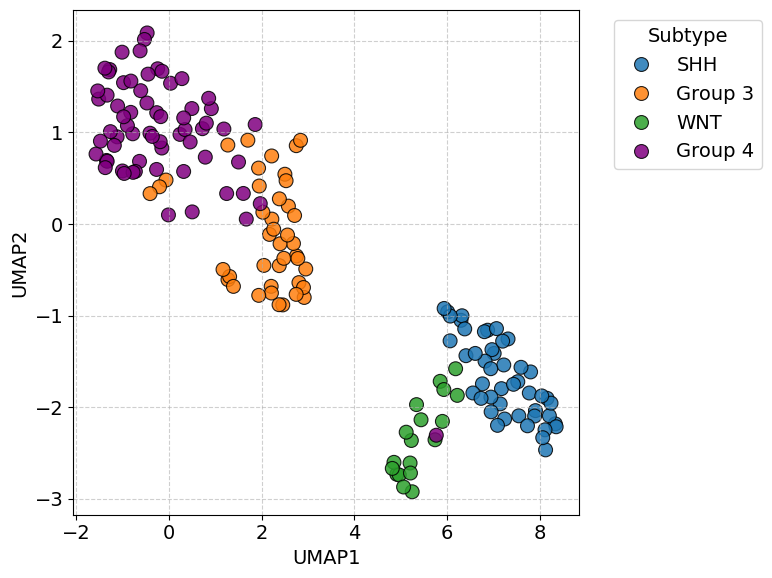

In [ ]:
freq_significant  = freq_ICGC[feature_scores[feature_scores['Adjusted_P_Value']< 0.01]['Feature']]


scaler = StandardScaler()
scaled_features = scaler.fit_transform(freq_significant)
custom_palette = { 'SHH': '#1f77b4', 'Group 3': '#ff7f0e', 'WNT': '#2ca02c', 'Group 4': 'purple' } 
# PCA on selected features
pca = PCA(n_components=2)
pca_components = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(data=pca_components, columns=['PC1', 'PC2'])
pca_df['Label'] = labels
pca_df['sample_name'] = freq_significant.index
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Label',
                s=100, alpha=0.85, edgecolor='black',
        palette=custom_palette)
# plt.title(f'PCA of Top {K} Features')


plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Optional: UMAP on selected features
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
umap_embedding = reducer.fit_transform(scaled_features)

umap_df = pd.DataFrame(umap_embedding, columns=['UMAP1', 'UMAP2'])
umap_df['Label'] = labels

plt.figure(figsize=(8, 6))
sns.scatterplot(data=umap_df, x='UMAP1', y='UMAP2', hue='Label',
                s=100, alpha=0.85, edgecolor='black', palette=custom_palette)
# plt.title(f'UMAP of Top {K} Features')
plt.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



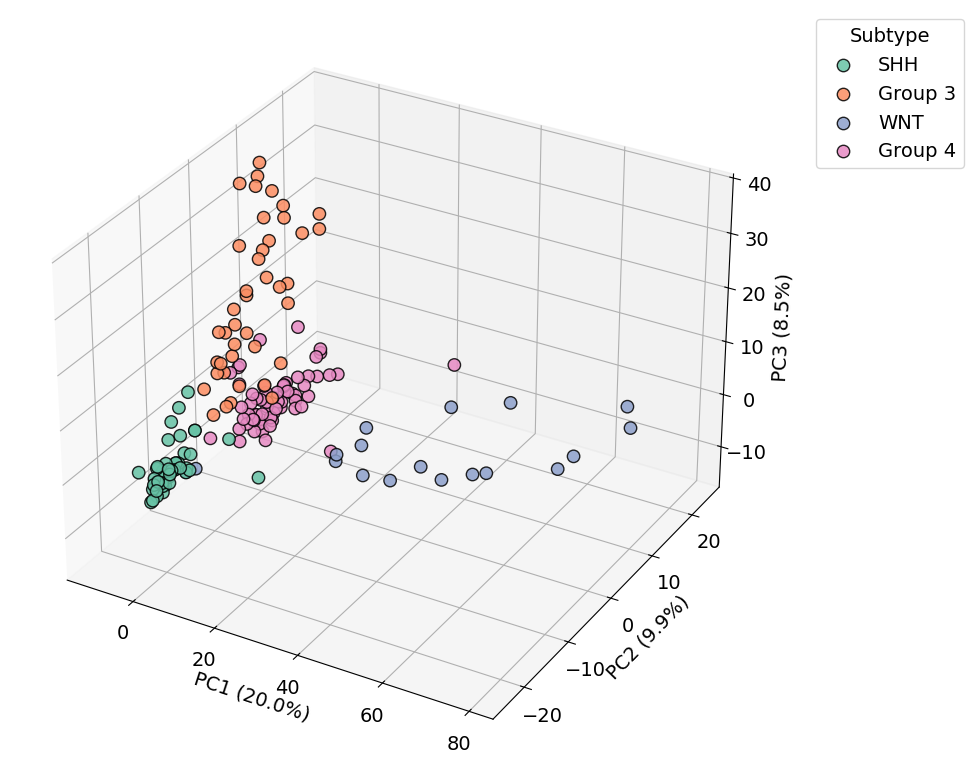

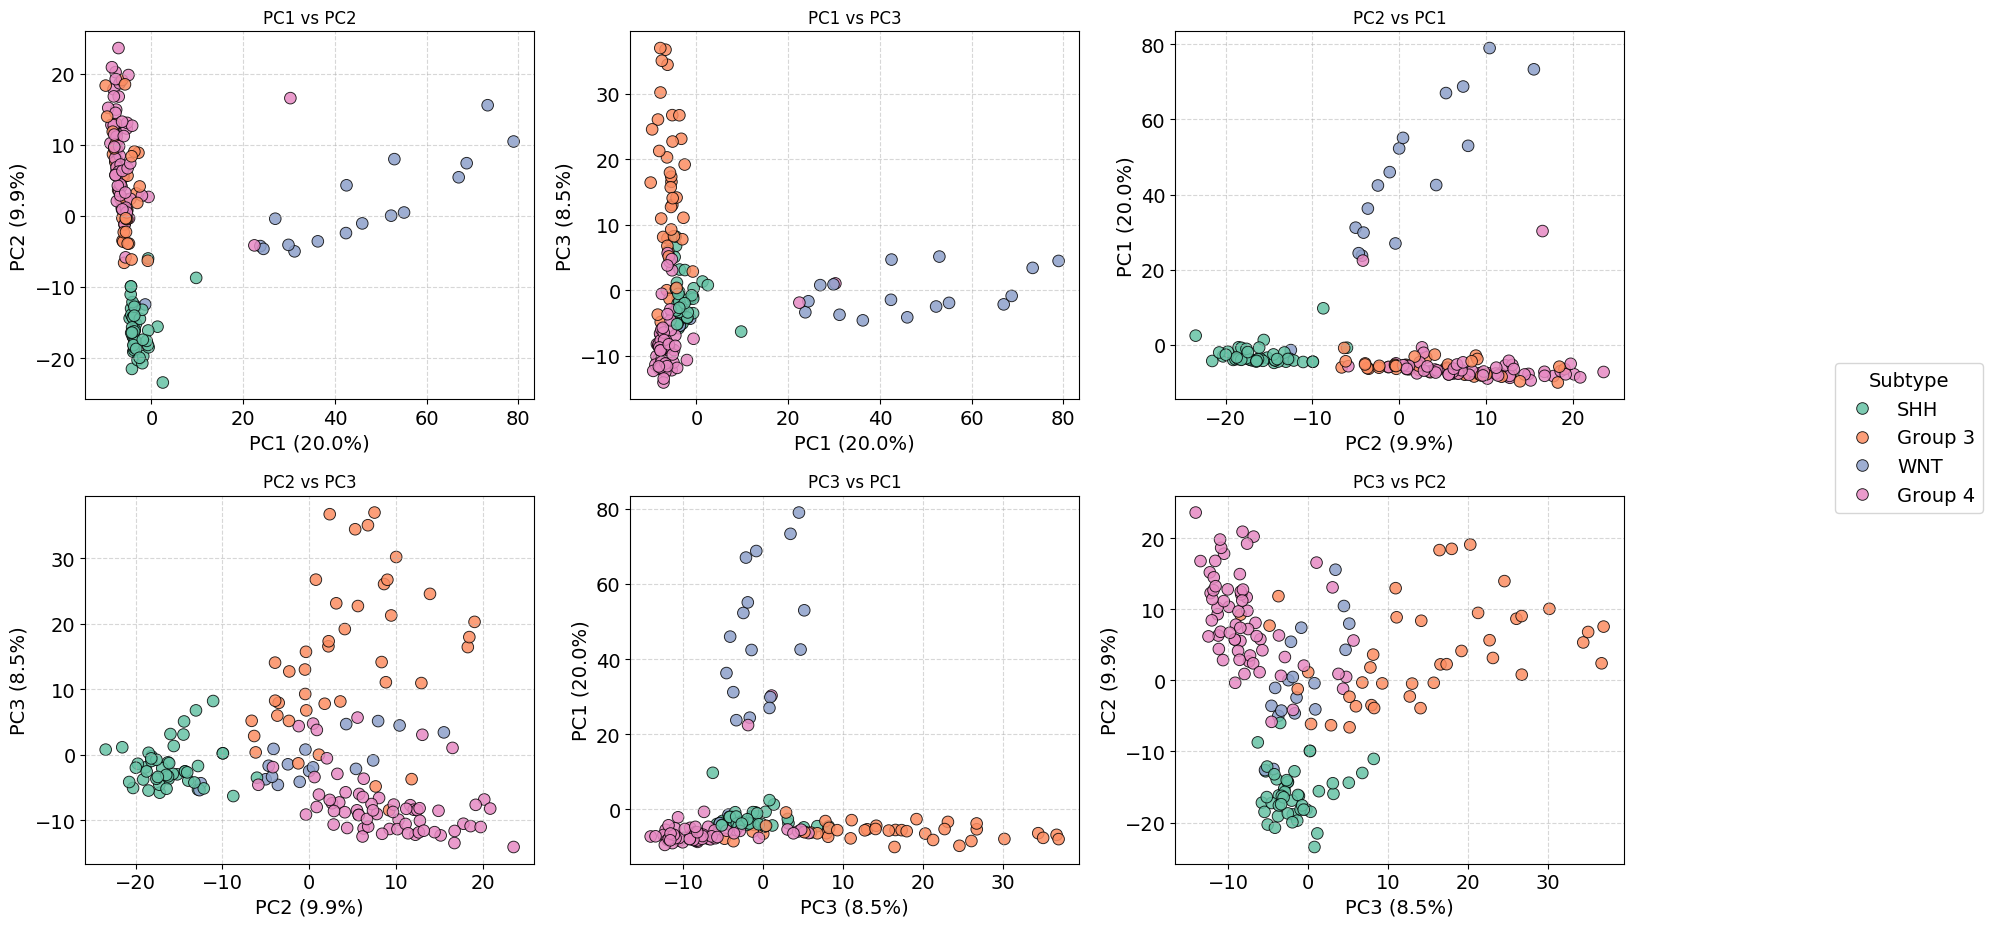

In [ ]:
import itertools

from mpl_toolkits.mplot3d import Axes3D  # required for 3D plotting

# PCA on selected features with 3 components
pca = PCA(n_components=3)
pca_components = pca.fit_transform(scaled_features)

# Create DataFrame with PCA components
pca_df = pd.DataFrame(data=pca_components, columns=['PC1', 'PC2', 'PC3'])
pca_df['Label'] = labels
pca_df['sample_name'] = freq_significant.index

# 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Convert label to categorical color
unique_labels = pca_df['Label'].unique()
palette = sns.color_palette("Set2", n_colors=len(unique_labels))
label_color_dict = dict(zip(unique_labels, palette))

# Scatter plot
for label in unique_labels:
    subset = pca_df[pca_df['Label'] == label]
    ax.scatter(subset['PC1'], subset['PC2'], subset['PC3'],
               label=label, s=80, alpha=0.85, edgecolor='black',
               color=label_color_dict[label])

# ax.set_title(f'3D PCA of Top {K} Features', fontsize=14)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)")
ax.legend(title='Subtype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
# plt.savefig(Fig_Dir+"/PCA_top2500_features.tiff", dpi= 600)
plt.show()


fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# List of components
components = ['PC1', 'PC2', 'PC3']
pairs = list(itertools.permutations(components, 2))  # all 6 ordered combinations

# Flatten axes for easy indexing
axes = axes.flatten()

# Plot each pair
for i, (x_comp, y_comp) in enumerate(pairs):
    ax = axes[i]
    sns.scatterplot(data=pca_df, x=x_comp, y=y_comp, hue='Label',
                    palette='Set2', s=70, alpha=0.85, edgecolor='black', ax=ax)
    ax.set_title(f'{x_comp} vs {y_comp}', fontsize=12)
    ax.set_xlabel(f"{x_comp} ({pca.explained_variance_ratio_[components.index(x_comp)]*100:.1f}%)")
    ax.set_ylabel(f"{y_comp} ({pca.explained_variance_ratio_[components.index(y_comp)]*100:.1f}%)")
    ax.legend().set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.5)

# Add shared legend outside
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, title='Subtype', bbox_to_anchor=(1.02, 0.5), loc='center left')

# plt.suptitle(f'Pairwise 2D PCA Projections of Top {K} Features', fontsize=16)
plt.tight_layout(rect=[0, 0, 0.92, 0.95])
plt.show()



import plotly.express as px

fig = px.scatter_3d(
    pca_df,
    x='PC1', y='PC2', z='PC3',
    color='Label',
    # title=f'3D PCA of Top {K} Features',
    
    labels={
        'PC1': f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)",
        'PC2': f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)",
        'PC3': f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)"
    },
    opacity=1
)
fig.update_traces(marker=dict(size=6, line=dict(width=0.5, color='black')))
fig.show()


In [ ]:
freq_significant.to_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\genome_information/freq_significant_selectKBest_1376.csv")

<>:9: SyntaxWarning:

invalid escape sequence '\B'

<>:9: SyntaxWarning:

invalid escape sequence '\B'

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\1666163734.py:9: SyntaxWarning:

invalid escape sequence '\B'



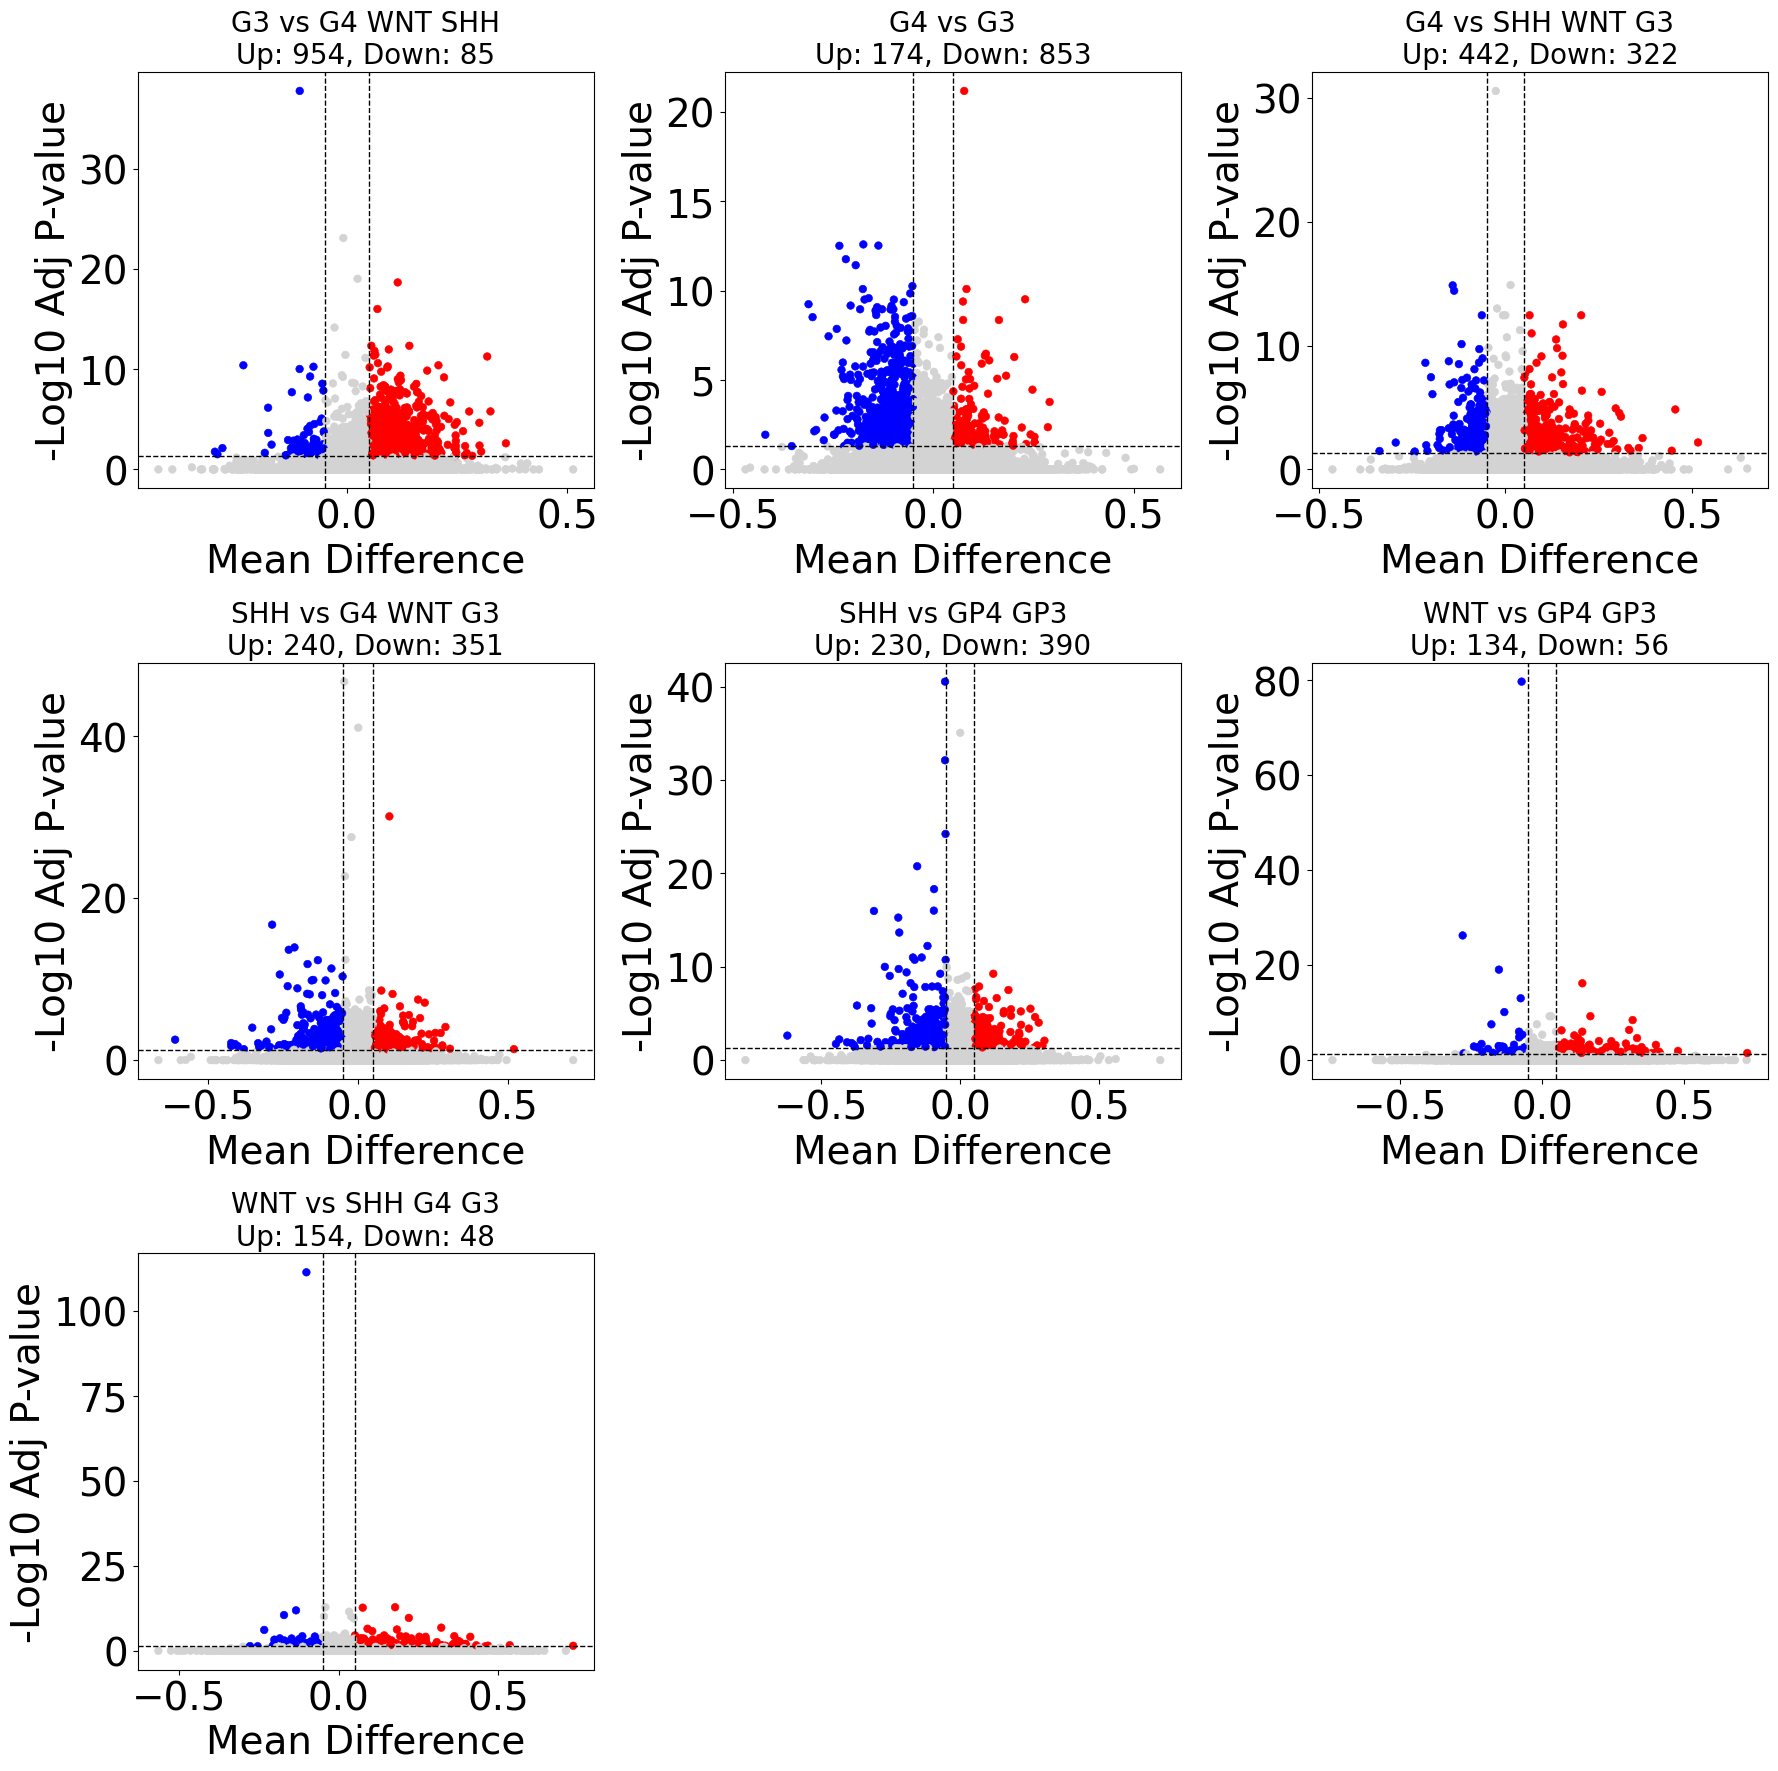

In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Directory
input_dir = "H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\Differenitally_edited_sites"
files = [f for f in os.listdir(input_dir) if f.startswith("Alt") and f.endswith(".txt")]

# Parameters
fc_thresh = 0.05
pval_thresh = 0.05
palette = {'Not Significant': 'lightgray', 'Upregulated': 'red', 'Downregulated': 'blue'}

# Setup grid size
n_files = len(files)
n_cols = 3
n_rows = math.ceil(n_files / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 6), squeeze=False)

# Loop through files and plot
for idx, filename in enumerate(sorted(files)):
    file_path = os.path.join(input_dir, filename)
    df = pd.read_csv(file_path, index_col=0)
    
    # Process data
    df['-log10_p'] = -np.log10(df['adj_p_values'])
    df['Significance'] = 'Not Significant'
    df.loc[(df['Diff_mean'] > fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['Diff_mean'] < -fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Downregulated'

    up_count = (df['Significance'] == 'Upregulated').sum()
    down_count = (df['Significance'] == 'Downregulated').sum()

    ax = axes[idx // n_cols][idx % n_cols]
    sns.scatterplot(data=df, x='Diff_mean', y='-log10_p', hue='Significance', palette=palette,
                    edgecolor=None, s=30, ax=ax, legend=False)
    
    ax.axhline(-np.log10(pval_thresh), color='black', linestyle='--', linewidth=1)
    ax.axvline(fc_thresh, color='black', linestyle='--', linewidth=1)
    ax.axvline(-fc_thresh, color='black', linestyle='--', linewidth=1)
    
    title = filename.replace("_input.txt", "")
    title = title.replace("Alt_REDIT_","")
    title = title.replace("_"," ")
    ax.set_title(f"{title}\nUp: {up_count}, Down: {down_count}", fontsize=20)
    ax.set_xlabel('Mean Difference', fontsize=28)
    ax.set_ylabel('-Log10 Adj P-value', fontsize=28)
    ax.tick_params(labelsize=28)

# Remove empty subplots if any
for i in range(n_files, n_rows * n_cols):
    fig.delaxes(axes[i // n_cols][i % n_cols])

plt.tight_layout()
plt.subplots_adjust(top=0.95)
# fig.suptitle("Volcano Plots with Significant Site Counts", fontsize=20)

# Save the whole panel
# plt.savefig(Fig_Dir+"/Cell_Deconvulution.tiff", dpi= 600)

# plt.savefig(Fig_Dir+"combined_volcano_panel.png", dpi=600)
plt.show()



In [ ]:
subgroup = A2G[A2G.index.str.contains("ICGC")][['subgroup','Sample']]

In [ ]:
subgroup.head()

,subgroup,Sample
ICGC_MB104,SHH,ICGC_MB104
ICGC_MB199,Group 4,ICGC_MB199
ICGC_MB99,Group 4,ICGC_MB99
ICGC_MB71,Group 4,ICGC_MB71
ICGC_MB288,Group 4,ICGC_MB288


In [ ]:
freq_ICGC = freq_ICGC.T

In [ ]:
freq_ICGC[subgroup[subgroup['subgroup']=='Group 3'].index].mean(axis=1)

chr10_100165863    0.008711
chr10_100165901    0.024390
chr10_100166202    0.000000
chr10_100208723    0.121951
chr10_100213660    0.000000
                     ...   
chrY_7373699       0.006707
chrY_7373700       0.019744
chrY_7374118       0.006652
chrY_7374959       0.024390
chrY_7380573       0.029049
Length: 119627, dtype: float64

In [ ]:
freq_ICGC[subgroup[(subgroup['subgroup']=='Group 4') | (subgroup['subgroup']=='SHH') | (subgroup['subgroup']=='WNT')].index].mean(axis=1)

chr10_100165863    0.007752
chr10_100165901    0.000000
chr10_100166202    0.002673
chr10_100208723    0.046767
chr10_100213660    0.023256
                     ...   
chrY_7373699       0.000000
chrY_7373700       0.000000
chrY_7374118       0.000000
chrY_7374959       0.000000
chrY_7380573       0.021504
Length: 119627, dtype: float64

In [ ]:
test= pd.read_csv("H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\Differenitally_edited_sites\Alt_REDIT_G3_vs_G4_WNT_SHH_input.txt", index_col=0)

<>:1: SyntaxWarning:

invalid escape sequence '\B'

<>:1: SyntaxWarning:

invalid escape sequence '\B'

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\2106094378.py:1: SyntaxWarning:

invalid escape sequence '\B'



In [ ]:
test.loc[freq_ICGC.index]

,ICGC_MB106,ICGC_MB111,ICGC_MB131,ICGC_MB134,ICGC_MB139,ICGC_MB141,ICGC_MB146,ICGC_MB16,ICGC_MB164,ICGC_MB165,...,ICGC_MB23,ICGC_MB276,ICGC_MB290,ICGC_MB31,ICGC_MB46,ICGC_MB54,p_values,adj_p_values,log_fold,Diff_mean
chr10_100165863,0,0,0,0,10,0,0,0,0,0,...,0,0,0,0,0,0,0.021688,0.310486,0.075895,0.000959
chr10_100165901,0,0,0,0,15,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,1.781999,0.024390
chr10_100166202,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,-0.341767,-0.002673
chr10_100208723,0,0,0,0,0,0,11,0,0,0,...,0,0,0,0,0,0,0.004829,0.133381,1.216876,0.075184
chr10_100213660,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,-1.733607,-0.023256
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_7373699,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,0.740480,0.006707
chrY_7373700,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,1.572622,0.019744
chrY_7374118,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,0.735685,0.006652
chrY_7374959,0,0,12,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1.000000,1.000000,1.781999,0.024390


In [ ]:
freq_ICGC[subgroup[(subgroup['subgroup']=='Group 4') | (subgroup['subgroup']=='SHH') | (subgroup['subgroup']=='WNT')].index].mean(axis=1) - freq_ICGC[subgroup[subgroup['subgroup']=='Group 3'].index].mean(axis=1)

chr10_100165863   -0.000959
chr10_100165901   -0.024390
chr10_100166202    0.002673
chr10_100208723   -0.075184
chr10_100213660    0.023256
                     ...   
chrY_7373699      -0.006707
chrY_7373700      -0.019744
chrY_7374118      -0.006652
chrY_7374959      -0.024390
chrY_7380573      -0.007545
Length: 119627, dtype: float64

## Exon plotted

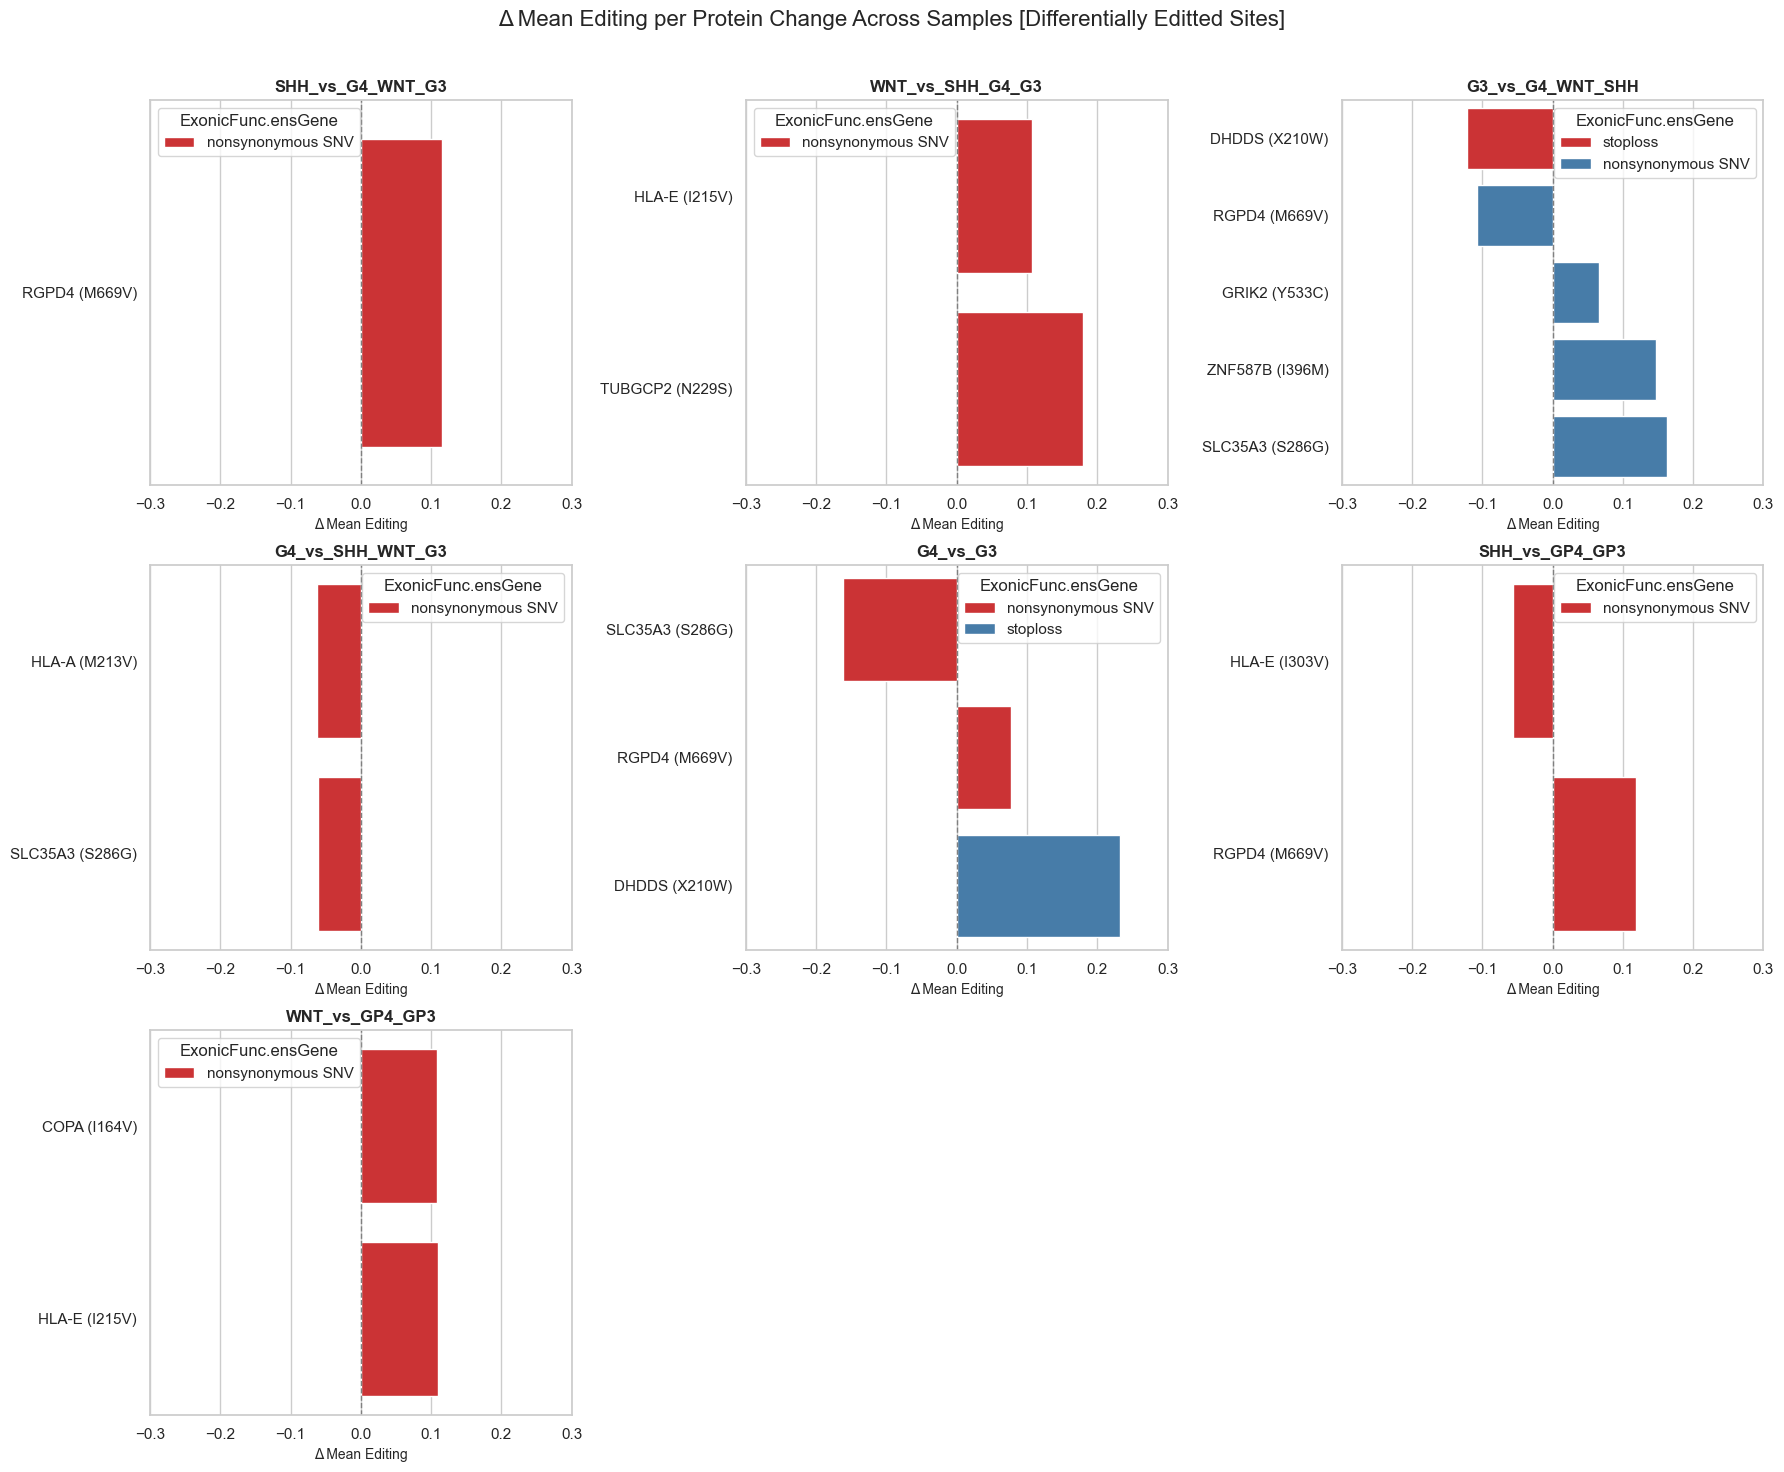

In [ ]:
import math

# Compute number of rows and columns for a square-like layout
n_files = len(files)
ncols = math.ceil(n_files**0.5)
nrows = math.ceil(n_files / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows), sharex=False)
axes = axes.flatten()  # Flatten to easily index

sns.set(style='whitegrid')

plot_idx = 0  # Index for placing subplot

for file in files:
    df = pd.read_csv(os.path.join(input_dir, file), index_col=0)
    name = file.replace("Alt_REDIT_", "").replace("_input.txt", "")

    # Process data
    df['-log10_p'] = -np.log10(df['adj_p_values'])
    df['Significance'] = 'Not Significant'
    df.loc[(df['Diff_mean'] > fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['Diff_mean'] < -fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Downregulated'

    # Filter and extract non-synonymous
    common_idx = df.index.intersection(exome.index)
    filtered_df = df.loc[common_idx]
    filtered_df = filtered_df[filtered_df['Significance'] != 'Not Significant']

    common_idx = 
    .index.intersection(filtered_df.index)
    exome_non_syn = exome.loc[common_idx]
    exome_non_syn = exome_non_syn[exome_non_syn['ExonicFunc.ensGene'] != 'synonymous SNV']

    if exome_non_syn.empty or plot_idx >= len(axes):
        continue

    temp = pd.DataFrame(df.loc[exome_non_syn.index]["Diff_mean"])
    temp['ExonicFunc.ensGene'] = exome_non_syn['ExonicFunc.ensGene']
    temp['modification'] = exome_non_syn['AAChange.ensGene']
    temp['protein_change'] = temp['modification'].str.extract(r'(p\.\w+\d+\w+)')
    temp['Gene_name'] = exome_non_syn['Gene.ensGene']
    temp['index'] = temp.apply(lambda row: f"{row['Gene_name']} ({row['protein_change'][2:]})", axis=1)
    temp_sorted = temp.sort_values(by='Diff_mean', ascending=True)

    ax = axes[plot_idx]
    sns.barplot(
        data=temp_sorted,
        x='Diff_mean',
        y='index',
        hue='ExonicFunc.ensGene',
        dodge=False,
        palette='Set1',
        ax=ax
    )

    ax.set_title(name, fontsize=12, weight='bold')
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_ylabel("")
    ax.set_xlabel("Δ Mean Editing", fontsize=10)
    # ax.legend(title='Exonic Function', loc='lower right', fontsize=12, title_fontsize=9)
    # ax.get_legend().remove()
    ax.set_xlim(-0.30,0.30)
    plot_idx += 1

# Hide unused subplots
for j in range(plot_idx, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.suptitle("Δ Mean Editing per Protein Change Across Samples [Differentially Editted Sites]", fontsize=16)
plt.show()


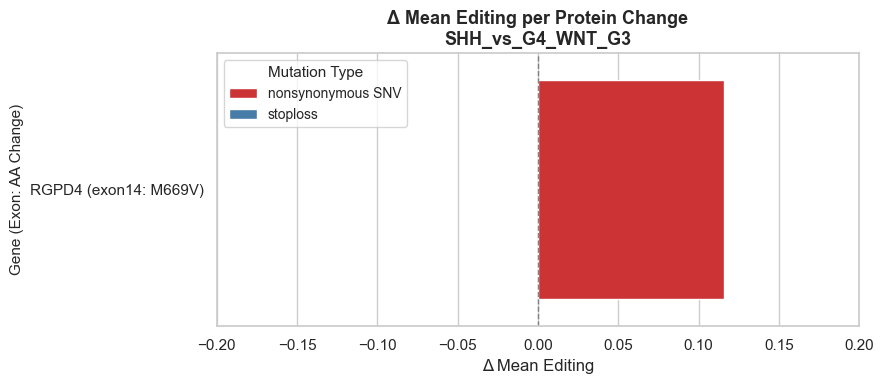

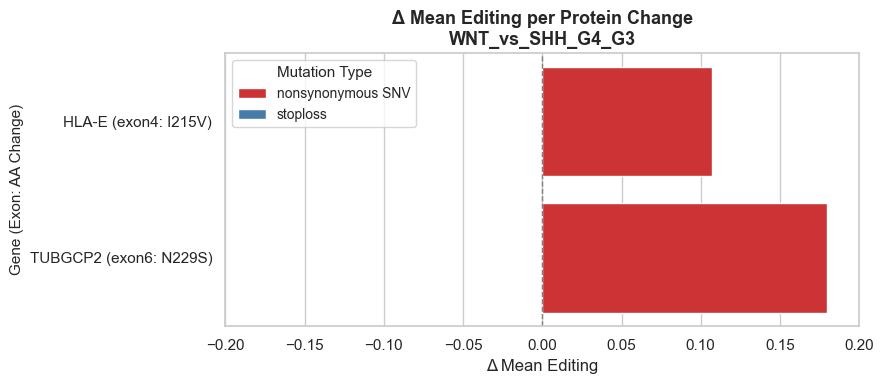

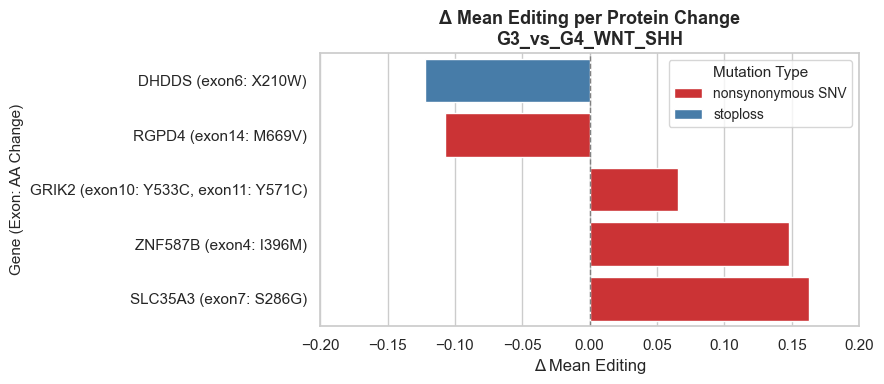

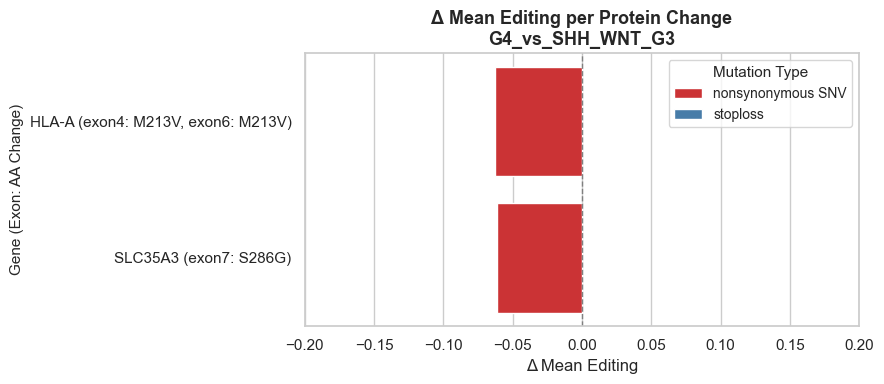

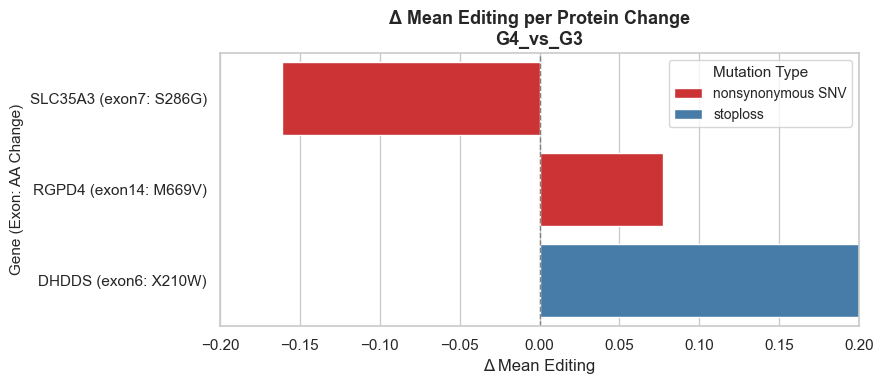

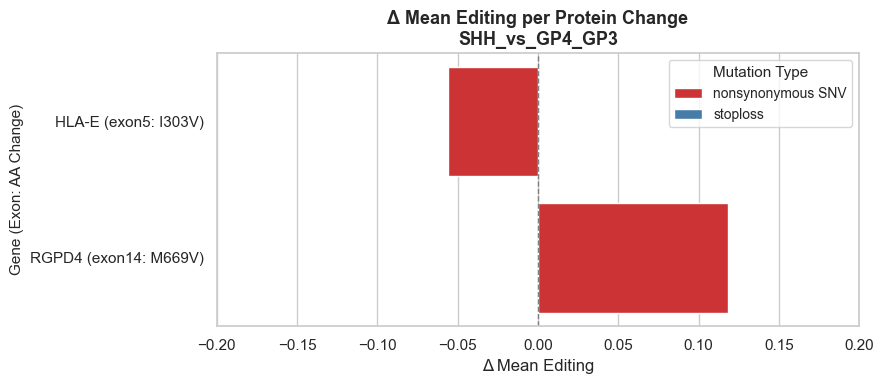

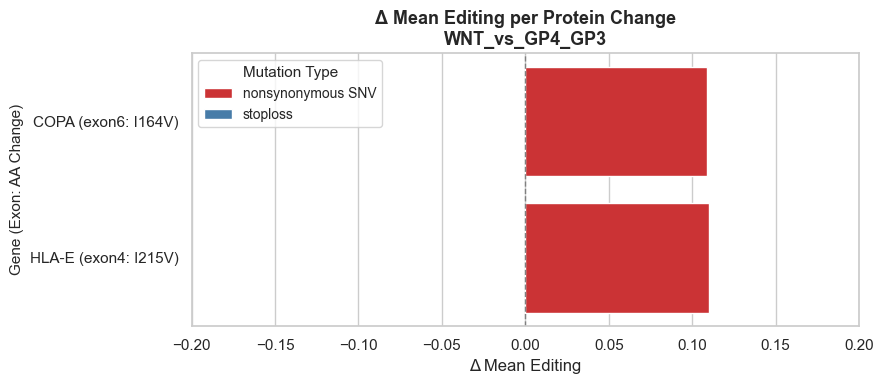

In [ ]:
import os
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Parameters
fc_thresh = 0.05
pval_thresh = 0.05

sns.set(style='whitegrid')

def parse_all_changes(modification_str):
    """Extract all (exon, protein_change) pairs from a modification string."""
    if pd.isna(modification_str):
        return []
    entries = modification_str.split(',')
    results = []
    for entry in entries:
        exon = re.search(r'(exon\d+)', entry)
        pchange = re.search(r'(p\.[A-Za-z]+\d+[A-Za-z]+)', entry)
        if exon and pchange:
            results.append(f"{exon.group(1)}:{pchange.group(1)}")
    return list(dict.fromkeys(results))

def build_gene_label(group):
    """Build combined label: 'MED25 (exon5: Y355C, exon6: K400R)'"""
    exon_parts = ', '.join(
        f"{row['exon']}: {row['protein_change'][2:]}"
        for _, row in group.iterrows()
    )
    return f"{group['Gene_name'].iloc[0]} ({exon_parts})"


# ── Pre-compute global x-axis limits AND global mutation-type color map ───
all_diff_means = []
all_categories = set()

for file in files:
    df_tmp = pd.read_csv(os.path.join(input_dir, file), index_col=0)
    if 'Diff_mean' in df_tmp.columns:
        all_diff_means.extend(df_tmp['Diff_mean'].dropna().tolist())

    # Same filtering logic as the main loop, just to harvest categories present
    df_tmp['Significance'] = 'Not Significant'
    df_tmp.loc[(df_tmp['Diff_mean'] > fc_thresh) & (df_tmp['adj_p_values'] < pval_thresh), 'Significance'] = 'Upregulated'
    df_tmp.loc[(df_tmp['Diff_mean'] < -fc_thresh) & (df_tmp['adj_p_values'] < pval_thresh), 'Significance'] = 'Downregulated'

    common_idx = df_tmp.index.intersection(exome.index)
    filtered_tmp = df_tmp.loc[common_idx]
    filtered_tmp = filtered_tmp[filtered_tmp['Significance'] != 'Not Significant']

    common_idx = exome.index.intersection(filtered_tmp.index)
    exome_tmp = exome.loc[common_idx]
    exome_tmp = exome_tmp[exome_tmp['ExonicFunc.ensGene'] != 'synonymous SNV']

    all_categories.update(exome_tmp['ExonicFunc.ensGene'].unique())

global_max = max(abs(min(all_diff_means)), abs(max(all_diff_means)))
global_xlim = (-global_max * 1.1, global_max * 1.1)  # 10% padding on both sides

all_categories = sorted(all_categories)
palette_colors = sns.color_palette('Set1', n_colors=len(all_categories))
color_map = dict(zip(all_categories, palette_colors))
# ───────────────────────────────────────────────────────────────────────────


for i, file in enumerate(files):
    df = pd.read_csv(os.path.join(input_dir, file), index_col=0)
    name = file.replace("Alt_REDIT_", "").replace("_input.txt", "")

    # Process data
    df['-log10_p'] = -np.log10(df['adj_p_values'])
    df['Significance'] = 'Not Significant'
    df.loc[(df['Diff_mean'] > fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Upregulated'
    df.loc[(df['Diff_mean'] < -fc_thresh) & (df['adj_p_values'] < pval_thresh), 'Significance'] = 'Downregulated'

    # Filter and extract non-synonymous
    common_idx = df.index.intersection(exome.index)
    filtered_df = df.loc[common_idx]
    filtered_df = filtered_df[filtered_df['Significance'] != 'Not Significant']

    common_idx = exome.index.intersection(filtered_df.index)
    exome_non_syn = exome.loc[common_idx]
    exome_non_syn = exome_non_syn[exome_non_syn['ExonicFunc.ensGene'] != 'synonymous SNV']

    if exome_non_syn.empty:
        continue

    # Build rows with all exon + amino acid change combinations
    rows = []
    for idx in exome_non_syn.index:
        diff_mean = df.loc[idx, 'Diff_mean']
        exonic_func = exome_non_syn.loc[idx, 'ExonicFunc.ensGene']
        modification = exome_non_syn.loc[idx, 'AAChange.ensGene']
        gene_name = exome_non_syn.loc[idx, 'Gene.ensGene']

        changes = parse_all_changes(modification)

        if not changes:
            continue

        for change in changes:
            exon_part, pchange = change.split(':')
            rows.append({
                'Diff_mean': diff_mean,
                'ExonicFunc.ensGene': exonic_func,
                'modification': modification,
                'exon': exon_part,
                'protein_change': pchange,
                'Gene_name': gene_name,
            })

    if not rows:
        continue

    temp = pd.DataFrame(rows).drop_duplicates(subset=['Gene_name', 'exon', 'protein_change'])

    # One row per gene with combined label
    gene_rows = []
    for gene, group in temp.groupby('Gene_name'):
        label = build_gene_label(group)
        gene_rows.append({
            'Gene_name': gene,
            'label': label,
            'Diff_mean': group['Diff_mean'].mean(),
            'ExonicFunc.ensGene': group['ExonicFunc.ensGene'].iloc[0],
        })

    temp_sorted = pd.DataFrame(gene_rows).sort_values(by='Diff_mean', ascending=True)

    # Plot
    fig, ax = plt.subplots(figsize=(9, max(4, len(temp_sorted) * 0.5)))

    sns.barplot(
        data=temp_sorted,
        x='Diff_mean',
        y='label',
        hue='ExonicFunc.ensGene',
        hue_order=all_categories,   # consistent hue ordering across files
        dodge=False,
        palette=color_map,          # fixed color per mutation type across all plots
        ax=ax
        # (legend defaults to True here — removed legend=False, which was
        #  suppressing the handles that ax.legend() then had nothing to draw)
    )

    ax.set_xlim(-0.2, 0.2)  # ← equal x-axis across all plots
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_xlabel("Δ Mean Editing", fontsize=12)
    ax.set_ylabel("Gene (Exon: AA Change)", fontsize=11)
    ax.set_title(f"Δ Mean Editing per Protein Change\n{name}", fontsize=13, weight='bold')
    ax.legend(title='Mutation Type', loc='best', fontsize=10, title_fontsize=11)

    plt.tight_layout()
    # plt.savefig(os.path.join(output_dir, f"{name}_barplot.png"), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

In [ ]:
selected_sites = pd.read_csv(r"H:\Bulk_medulloblastoma_A_to_I_editing_finalized\ICGC_Only_Analysis\data\genome_information\freq_significant_selectKBest_1376.csv",index_col=0)

In [ ]:
selected_sites

,chr6_42889288,chr2_29030183,chr16_50577404,chr12_65058930,chr16_50576801,chrX_48577960,chr15_28807046,chr2_177627724,chr16_50580487,chr2_237382261,...,chr7_88865047,chr5_15672689,chr19_52408283,chr5_116446269,chr14_20324894,chr6_7119214,chr2_32309752,chr7_128503552,chr13_99805061,chr7_18253106
ICGC_MB1,0.000000,0.0,0.0,0.0,0.0,0.000000,0.673077,0.0,0.0,0.0,...,0.0,0.0,0.198020,0.250720,1.0,0.000000,0.0,0.000000,0.0,0.0
ICGC_MB101,0.000000,0.0,0.0,0.0,0.0,0.000000,1.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.105477,1.0,0.000000,0.0,0.000000,0.0,0.0
ICGC_MB102,0.000000,0.0,0.0,0.0,0.0,0.000000,1.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.191038,0.0,0.000000,0.0,0.000000,0.0,0.0
ICGC_MB104,0.000000,0.0,0.0,0.0,0.0,0.000000,1.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.186047,0.0,0.000000,0.0,0.000000,0.0,0.0
ICGC_MB106,0.031457,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,1.0,0.000000,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ICGC_MB94,0.000000,0.0,0.0,0.0,0.0,0.052301,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.305556,0.000000,0.0,0.000000,0.0,0.000000,0.0,1.0
ICGC_MB95,0.051630,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.370370,0.151163,1.0,0.614035,0.0,0.166667,0.0,0.0
ICGC_MB96,0.033079,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,1.0
ICGC_MB98,0.070000,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.093333,0.0,1.0


In [ ]:
selected_sites = ICGC_genome.loc[selected_sites.columns]

In [ ]:

def plot_site_boxplot(freq_df, subgroup_df, site, name=None):
    """
    Boxplot + stripplot + stats for a single editing site across subgroups,
    matching the style of plotter_subgroups_ADAR_OEL.

    freq_df:     sites x samples matrix (e.g. freq_ICGC)
    subgroup_df: dataframe indexed by sample, with a 'subgroup' column
    site:        row label to plot, e.g. 'chr11_105933968'
    name:        y-axis label (defaults to the site name)
    """
    if name is None:
        name = site

    orders = ['SHH', 'Group 3', 'WNT', 'Group 4']
    custom_palette = {
        'SHH': '#1f77b4',
        'Group 3': '#ff7f0e',
        'WNT': '#2ca02c',
        'Group 4': 'purple'
    }

    # Build a long-format dataframe: one row per sample, subgroup + value at this site
    records = []
    for sg in orders:
        samples = subgroup_df[subgroup_df['subgroup'] == sg].index
        samples = samples.intersection(freq_df.columns)
        vals = freq_df.loc[site, samples]
        for s, v in vals.items():
            records.append({'sample': s, 'subgroup': sg, 'value': v})

    site_df = pd.DataFrame(records)

    pairs = list(combinations(orders, 2))

    plt.figure(figsize=(8, 6))
    ax = sns.boxplot(
        data=site_df, x="subgroup", y="value",
        palette=custom_palette, showfliers=False, order=orders
    )
    sns.stripplot(
        data=site_df, x="subgroup", y="value",Q
        color="black", size=4, jitter=True, alpha=0.6, ax=ax, order=orders
    )

    annotator = Annotator(ax, pairs, data=site_df, x="subgroup", y="value")
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', fontsize=14)
    annotator.apply_and_annotate()

    plt.xlabel("Subgroup", fontsize=28)
    plt.ylabel(name, fontsize=28)
    plt.xticks(rotation=45, fontsize=28)
    plt.yticks(fontsize=28)
    plt.title(site)
    plt.grid(False)
    plt.tight_layout()
    # plt.savefig(Fig_dir + f"/{site}_subgroup.tiff", dpi=600)
    plt.show()



In [ ]:
selected_sites[(selected_sites['Func.ensGene'] == "exonic") & (selected_sites['ExonicFunc.ensGene'] == "nonsynonymous SNV") ]

,Chr,Start,End,Ref,Alt,Func.ensGene,Gene.ensGene,GeneDetail.ensGene,ExonicFunc.ensGene,AAChange.ensGene,...,gnomad41_genome_AF_ami,gnomad41_genome_AF_amr,gnomad41_genome_AF_asj,gnomad41_genome_AF_eas,gnomad41_genome_AF_fin,gnomad41_genome_AF_mid,gnomad41_genome_AF_nfe,gnomad41_genome_AF_remaining,gnomad41_genome_AF_sas,Otherinfo1
chr11_105933968,chr11,105933968,105933968,A,G,exonic,GRIA4,NaN,nonsynonymous SNV,GRIA4:ENST00000525187.5:exon13:c.A2293G:p.R765...,...,.,.,.,.,.,.,.,.,.,+
chr8_102829408,chr8,102829408,102829408,T,C,exonic,AZIN1,NaN,nonsynonymous SNV,AZIN1:ENST00000337198.9:exon11:c.A1099G:p.S367...,...,0,0,0,0,0,0,0,0,0,-
chr3_62438132,chr3,62438132,62438132,T,C,exonic,CADPS,NaN,nonsynonymous SNV,"CADPS:ENST00000613879.4:exon6:c.A356G:p.E119G,...",...,.,.,.,.,.,.,.,.,.,-
chr18_35246147,chr18,35246147,35246147,A,G,exonic,ZNF397,NaN,nonsynonymous SNV,ZNF397:ENST00000330501.11:exon4:c.A1442G:p.Y481C,...,.,.,.,.,.,.,.,.,.,+
chr5_179720537,chr5,179720537,179720537,A,G,exonic,CANX,NaN,nonsynonymous SNV,CANX:ENST00000247461.8:exon10:c.A1159G:p.M387V...,...,.,.,.,.,.,.,.,.,.,+


In [ ]:
mutate_sites = selected_sites[(selected_sites['Func.ensGene'] == "exonic") & (selected_sites['ExonicFunc.ensGene'] == "nonsynonymous SNV") ].index


C:\Users\17867\AppData\Local\Temp\ipykernel_30600\873503945.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.405e-11 U_stat=1.620e+03
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:8.348e-03 U_stat=3.075e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.001e-02 U_stat=6.720e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:6.346e-04 U_stat=6.335e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:4.384e-01 U_stat=1.312e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:3.361e-14 U_stat=2.530e+03


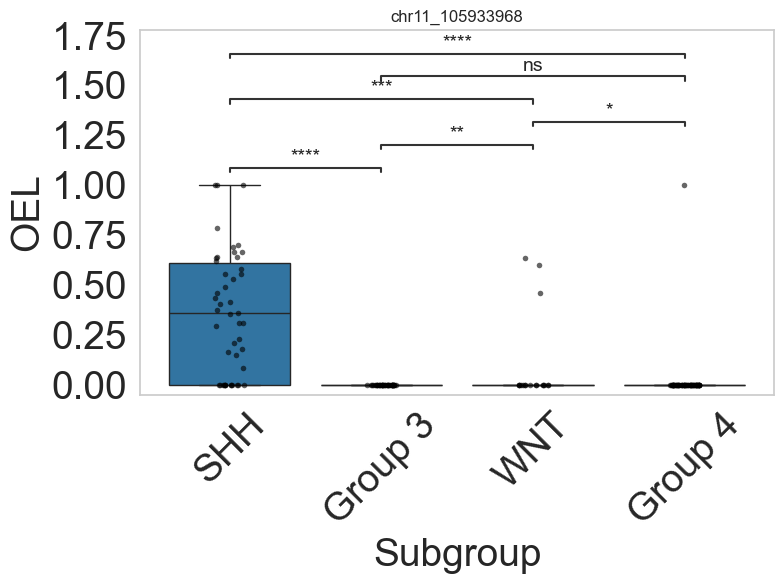

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\873503945.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.673e-12 U_stat=2.530e+02
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:2.293e-06 U_stat=6.390e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.103e-04 U_stat=2.880e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=4.140e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:9.968e-05 U_stat=1.912e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.924e-08 U_stat=7.360e+02


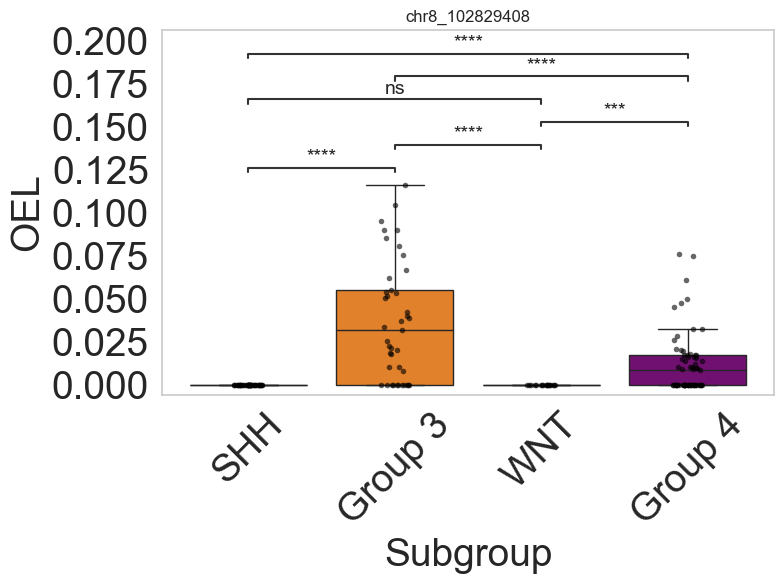

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\873503945.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.814e-09 U_stat=2.630e+02
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:8.369e-01 U_stat=3.560e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:3.146e-01 U_stat=6.765e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:2.022e-06 U_stat=1.250e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.844e-01 U_stat=1.498e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:9.464e-11 U_stat=4.330e+02


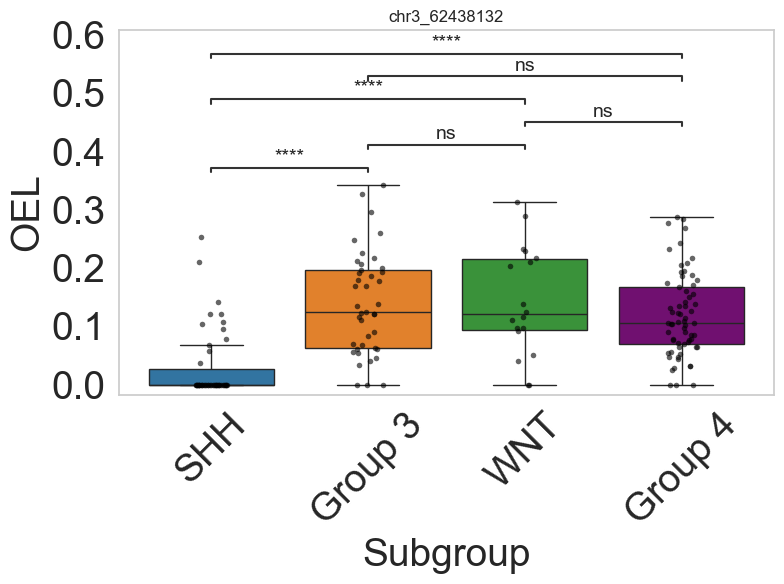

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\873503945.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.268e-05 U_stat=6.440e+02
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:8.194e-03 U_stat=4.860e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=5.850e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=4.140e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.552e-06 U_stat=1.755e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=1.495e+03


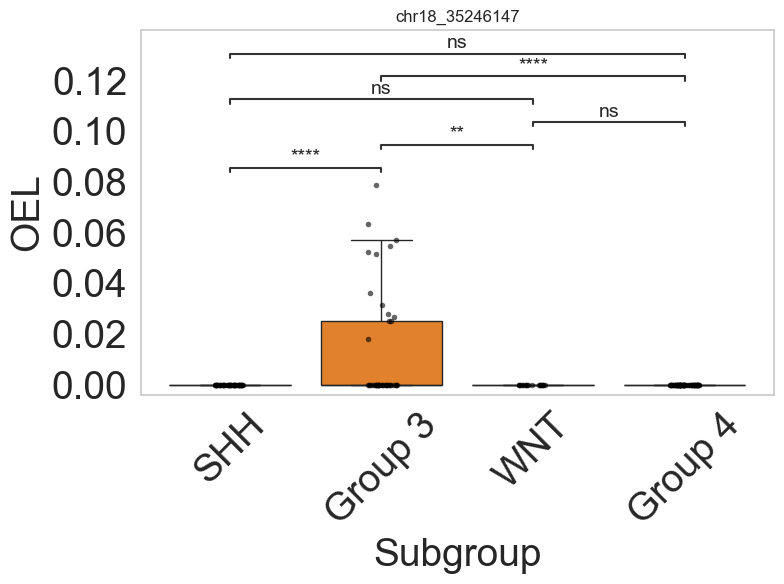

C:\Users\17867\AppData\Local\Temp\ipykernel_30600\873503945.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.654e-04 U_stat=1.210e+03
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=3.690e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=5.850e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.333e-02 U_stat=5.310e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=1.332e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:6.074e-06 U_stat=1.918e+03


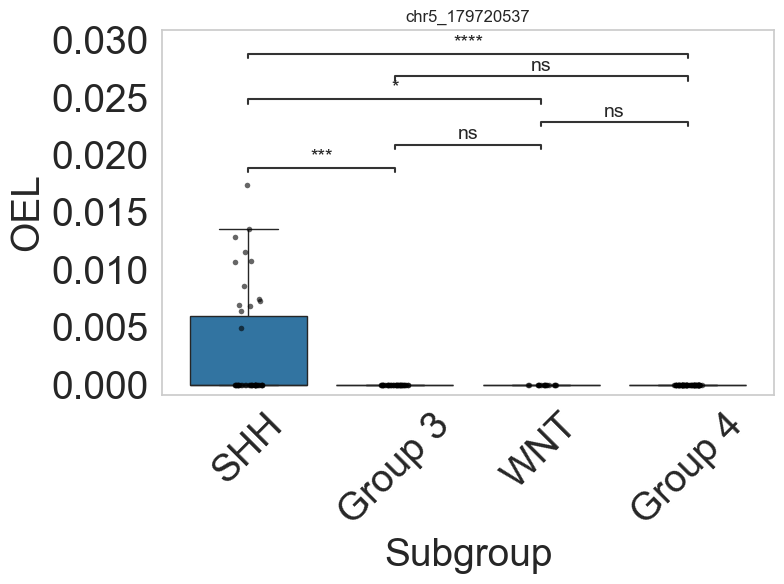

In [ ]:
for site in mutate_sites:
    plot_site_boxplot(
    freq_ICGC, subgroup, site,
    name='OEL')

In [ ]:
freq_ICGC.loc[['chr11_105933968']][subgroup[subgroup['subgroup']=="SHH"].index]
freq_ICGC.loc[['chr11_105933968']][subgroup[subgroup['subgroup']=="WNT"].index]
freq_ICGC.loc[['chr11_105933968']][subgroup[subgroup['subgroup']=="Group 4"].index]
freq_ICGC.loc[['chr11_105933968']][subgroup[subgroup['subgroup']=="Group 3"].index]


,ICGC_MB278,ICGC_MB39,ICGC_MB50,ICGC_MB5,ICGC_MB248,ICGC_MB146,ICGC_MB36,ICGC_MB226,ICGC_MB198,ICGC_MB141,...,ICGC_MB134,ICGC_MB289,ICGC_MB260,ICGC_MB90,ICGC_MB296,ICGC_MB166,ICGC_MB291,ICGC_MB106,ICGC_MB235,ICGC_MB45
chr11_105933968,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
A2G = pd.read_csv("E:/MB_Bulk_RNA_seq/retest_paired_end_correction\False_positive_filter/Bulk_MB_Analysis_Data//Edit_summary.csv", index_col=0)
A2G = A2G[A2G.index.str.contains("ICGC")]

<>:1: SyntaxWarning: invalid escape sequence '\F'
<>:1: SyntaxWarning: invalid escape sequence '\F'
C:\Users\17867\AppData\Local\Temp\ipykernel_24184\215332176.py:1: SyntaxWarning: invalid escape sequence '\F'
  A2G = pd.read_csv("E:/MB_Bulk_RNA_seq/retest_paired_end_correction\False_positive_filter/Bulk_MB_Analysis_Data//Edit_summary.csv", index_col=0)


In [9]:
scores = pd.read_csv("E:/MB_Bulk_RNA_seq/retest_paired_end_correction/cibersort_result//immune_scores.csv", index_col=0)
scores = scores[scores.index.str.contains("ICGC")]

In [10]:
A2G.head()

,StrandDecidingMethod,Sample,A2GEditingIndex,OEI,subgroup,ENSG00000197381.18|ADARB1,ENSG00000160710.18|ADAR,ENSG00000205696.5|ADARB2-AS1,ENSG00000185736.16|ADARB2
ICGC_MB104,RefSeqThenMMSites,ICGC_MB104,0.916336,0.124132,SHH,3.266106,6.771000,1.319683,3.650679
ICGC_MB199,RefSeqThenMMSites,ICGC_MB199,0.768636,0.120874,Group 4,5.862994,7.207365,0.000000,0.981981
ICGC_MB99,RefSeqThenMMSites,ICGC_MB99,0.780258,0.163154,Group 4,5.645414,6.542104,0.000000,0.846539
ICGC_MB71,RefSeqThenMMSites,ICGC_MB71,0.638814,0.102968,Group 4,3.867989,7.593870,0.000000,0.573463
ICGC_MB288,RefSeqThenMMSites,ICGC_MB288,0.656661,0.097541,Group 4,5.680635,8.678917,0.499401,5.183777


In [11]:
scores[['ADARB1', 'ADAR', 'ADARB2-AS1', 'ADARB2','A2GEditingIndex']] = A2G[
    ['ENSG00000197381.18|ADARB1',
     'ENSG00000160710.18|ADAR',
     'ENSG00000205696.5|ADARB2-AS1',
     'ENSG00000185736.16|ADARB2','A2GEditingIndex']
]

In [20]:
def plotter_subgroups_ADAR_OEL(Edt_smry, plotting = "OEL", name = "OEL"):
    import itertools
    from itertools import combinations
    from statannotations.Annotator import Annotator

    # Define custom palette
    custom_palette = {
        'SHH': '#1f77b4',
        'Group 3': '#ff7f0e',
        'WNT': '#2ca02c',
        'Group 4': 'purple'
    }
    orders = ['SHH', 'Group 3', 'WNT', 'Group 4']
    # Define all pairwise combinations
    # groups = Edt_smry['subgroup'].unique()
    groups = ['SHH', 'Group 3', 'WNT', 'Group 4']
    pairs = list(combinations(groups, 2))

    # Create plot
    plt.figure(figsize=(8, 6))
    ax = sns.boxplot(data=Edt_smry, x="Subgroup", y=f"{plotting}", palette=custom_palette, showfliers=False, order=orders)

    # Optional: add individual points
    sns.stripplot(data=Edt_smry, x="Subgroup", y=f"{plotting}", color="black", size=4, jitter=True, alpha=0.6, ax=ax, order=orders)

    # Annotate statistical comparisons
    annotator = Annotator(ax, pairs, data=Edt_smry, x="Subgroup", y=f"{plotting}")
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', fontsize=14)
    annotator.apply_and_annotate()

    # Final styling
    # plt.title("Overall Editing Level by Subgroup", fontsize=16)
    plt.xlabel("Subgroup", fontsize=28)
    plt.ylabel(f"{name}", fontsize=28)
    plt.xticks(rotation=45, fontsize=28)
    plt.yticks(fontsize=28)
    # plt.ylim(0,14)
    plt.grid(False)
    plt.tight_layout()
    # plt.savefig(Fig_dir+"/ADARB2_subgroup.tiff",dpi = 600)
    plt.show();


C:\Users\17867\AppData\Local\Temp\ipykernel_24184\3137466506.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=Edt_smry, x="Subgroup", y=f"{plotting}", palette=custom_palette, showfliers=False, order=orders)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.315e-01 U_stat=8.500e+02
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:9.141e-06 U_stat=6.390e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.884e-06 U_stat=1.745e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:3.296e-06 U_stat=7.260e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.125e-02 U_stat=1.634e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.622e-01 U_stat=1.729e+03


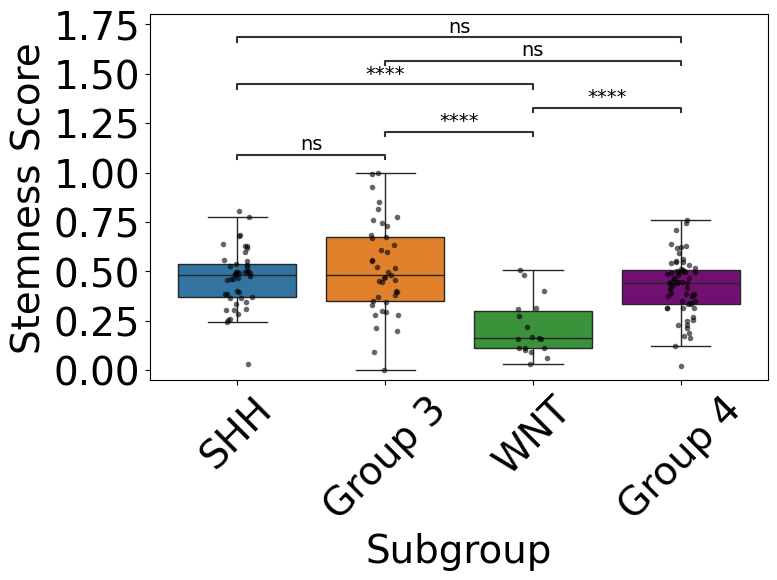

C:\Users\17867\AppData\Local\Temp\ipykernel_24184\3137466506.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=Edt_smry, x="Subgroup", y=f"{plotting}", palette=custom_palette, showfliers=False, order=orders)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SHH vs. Group 3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.656e-05 U_stat=4.360e+02
Group 3 vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.323e-02 U_stat=5.200e+02
WNT vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:9.303e-02 U_stat=4.325e+02
SHH vs. WNT: Mann-Whitney-Wilcoxon test two-sided, P_val:1.496e-01 U_stat=3.170e+02
Group 3 vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:4.815e-01 U_stat=1.442e+03
SHH vs. Group 4: Mann-Whitney-Wilcoxon test two-sided, P_val:7.885e-05 U_stat=8.350e+02


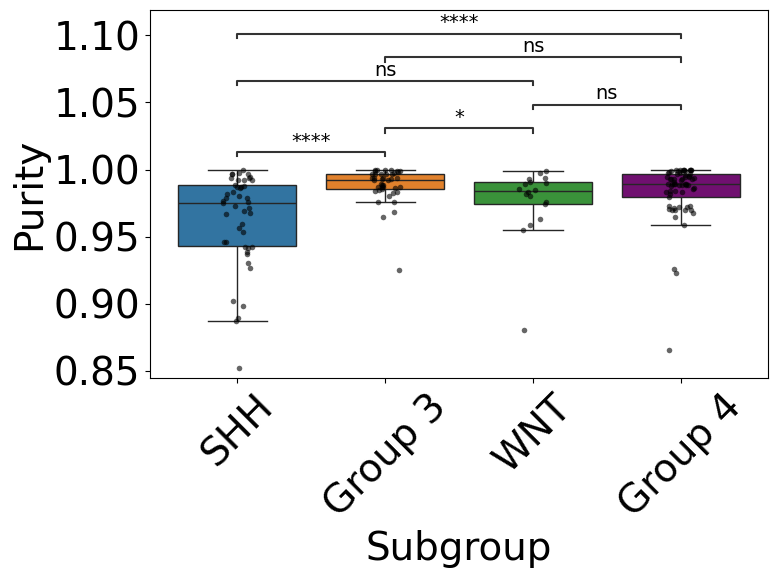

In [21]:
plotter_subgroups_ADAR_OEL(scores, plotting='stemness_score', name='Stemness Score')
plotter_subgroups_ADAR_OEL(scores, plotting='purity', name='Purity')


In [22]:
def overall_linear_plotter(OEL_ADAR, ADAR="ENSG00000160710.18|ADAR", gene_label="ADAR", x_comp="OEL", y_name='Stemness Score'):
    # Define custom palette (still used for coloring points by subgroup, purely visual)
    custom_palette = {
        'SHH': '#1f77b4',
        'Group 3': '#ff7f0e',
        'WNT': '#2ca02c',
        'Group 4': 'purple'
    }

    # Prepare the data
    X = OEL_ADAR[f'{x_comp}'].values
    y = OEL_ADAR[ADAR].values
    z = OEL_ADAR['Subgroup']

    plt.figure(figsize=(8, 6))

    # Scatter all points, colored by subgroup just for reference
    for subgroup in np.unique(z):
        mask = z == subgroup
        plt.scatter(X[mask], y[mask],
                    color=custom_palette.get(subgroup, 'gray'),
                    alpha=0.6, edgecolor='k',
                    label=subgroup)

    # Single regression line across ALL data (not split by subgroup)
    slope, intercept, r_value, p_value, std_err = linregress(X, y)

    line_X = np.linspace(X.min(), X.max(), 100)
    line_y = slope * line_X + intercept
    plt.plot(line_X, line_y, color='red', linestyle='-', linewidth=2, label='Overall fit')

    # Labels and title
    plt.xlabel(f'{y_name}', fontsize=28)
    plt.ylabel(rf"{gene_label} (log2(CPM+1))", fontsize=28)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    # plt.legend(title='Subgroup')
    plt.tight_layout()
    plt.show()

    # Print overall regression summary
    print(f"Overall: slope = {slope:.3f}, r = {r_value:.3f}, p = {p_value:.3e}")

NameError: name 'linregress' is not defined

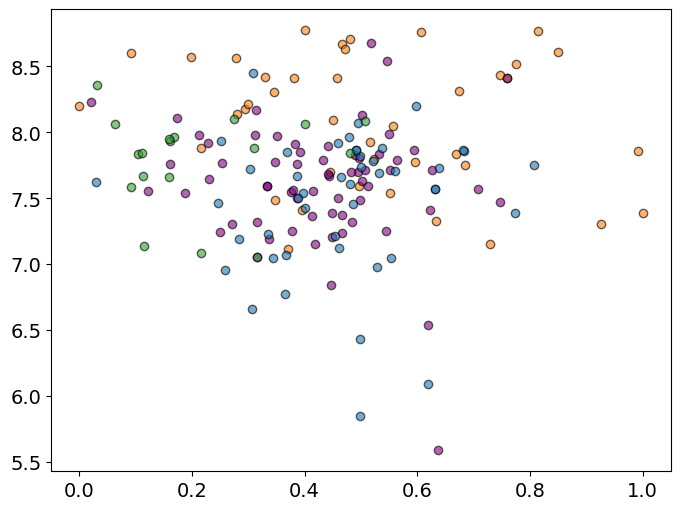

In [23]:
overall_linear_plotter(scores, ADAR="ADAR", gene_label="ADAR", x_comp="stemness_score")
overall_linear_plotter(scores, ADAR="ADARB1", gene_label="ADARB1", x_comp="stemness_score")
overall_linear_plotter(scores, ADAR="ADARB2", gene_label="ADARB2", x_comp="stemness_score")


NameError: name 'linregress' is not defined

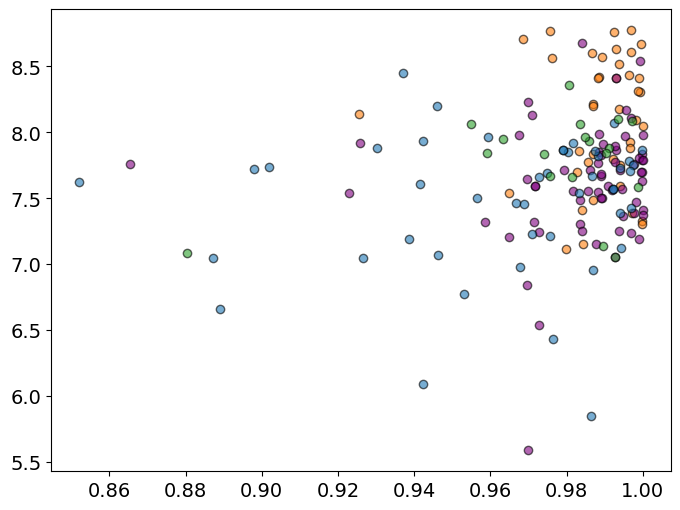

In [24]:
overall_linear_plotter(scores, ADAR="ADAR", gene_label="ADAR", x_comp="purity", y_name="Purity")
overall_linear_plotter(scores, ADAR="ADARB1", gene_label="ADARB1", x_comp="purity", y_name="Purity")
overall_linear_plotter(scores, ADAR="ADARB2", gene_label="ADARB2", x_comp="purity", y_name="Purity")


In [25]:
def overall_linear_plotter(OEL_ADAR, ADAR="ENSG00000160710.18|ADAR", gene_label="ADAR", x_comp="OEL", y_name='Stemness Score'):
    # Define custom palette (still used for coloring points by subgroup, purely visual)
    custom_palette = {
        'SHH': '#1f77b4',
        'Group 3': '#ff7f0e',
        'WNT': '#2ca02c',
        'Group 4': 'purple'
    }

    # Prepare the data
    X = OEL_ADAR[f'{x_comp}'].values
    y = OEL_ADAR[ADAR].values
    z = OEL_ADAR['Subgroup']

    plt.figure(figsize=(8, 6))

    # Scatter all points, colored by subgroup just for reference
    for subgroup in np.unique(z):
        mask = z == subgroup
        plt.scatter(X[mask], y[mask],
                    color=custom_palette.get(subgroup, 'gray'),
                    alpha=0.6, edgecolor='k',
                    label=subgroup)

    # Single regression line across ALL data (not split by subgroup)
    slope, intercept, r_value, p_value, std_err = linregress(X, y)

    line_X = np.linspace(X.min(), X.max(), 100)
    line_y = slope * line_X + intercept
    plt.plot(line_X, line_y, color='red', linestyle='-', linewidth=2, label='Overall fit')

    # Labels and title
    plt.xlabel(f'{y_name}', fontsize=28)
    plt.ylabel(rf"{gene_label}", fontsize=28)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    # plt.legend(title='Subgroup')
    plt.tight_layout()
    plt.show()

    # Print overall regression summary
    print(f"Overall: slope = {slope:.3f}, r = {r_value:.3f}, p = {p_value:.3e}")

NameError: name 'linregress' is not defined

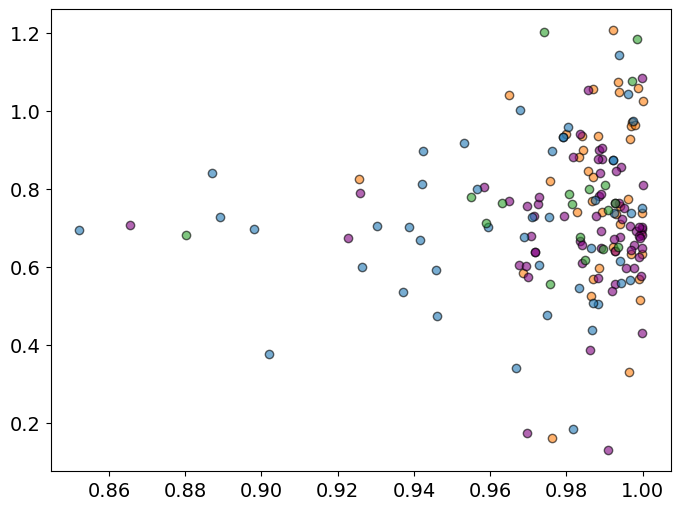

In [26]:
overall_linear_plotter(scores, ADAR="A2GEditingIndex", gene_label="AEI", x_comp="purity", y_name="Purity")
overall_linear_plotter(scores, ADAR="A2GEditingIndex", gene_label="AEI", x_comp="stemness_score", y_name="Stemness Score")
# overall_linear_plotter(scores, ADAR="ADARB2", gene_label="ADARB2", x_comp="purity", y_name="Purity")


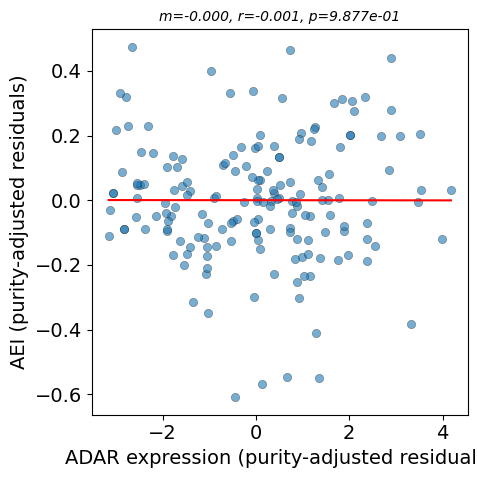

In [33]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats

# df should have columns: 'AEI', 'ADAR', 'ADARB1', 'ADARB2', 'Purity'

def partial_corr_and_residuals(df, x_col, y_col, covar_col):
    """Regress out covariate from x and y, return residuals + partial correlation stats"""
    # Regress x on covariate
    X_cov = sm.add_constant(df[covar_col])
    resid_x = sm.OLS(df[x_col], X_cov).fit().resid
    
    # Regress y on covariate
    resid_y = sm.OLS(df[y_col], X_cov).fit().resid
    
    # Partial correlation = correlation of residuals
    r, p = stats.pearsonr(resid_x, resid_y)
    m, b = np.polyfit(resid_x, resid_y, 1)
    
    return resid_x, resid_y, r, p, m

# Example: ADAR vs AEI, controlling for purity
resid_ADAR, resid_AEI, r, p, m = partial_corr_and_residuals(scores, 'ADARB2', 'A2GEditingIndex', 'purity')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(resid_ADAR, resid_AEI, alpha=0.6, edgecolor='k', linewidth=0.3)

# regression line
xs = np.linspace(resid_ADAR.min(), resid_ADAR.max(), 100)
ax.plot(xs, m*xs + np.polyfit(resid_ADAR, resid_AEI, 1)[1], color='red')

ax.set_xlabel('ADAR expression (purity-adjusted residuals)')
ax.set_ylabel('AEI (purity-adjusted residuals)')
ax.set_title(f'm={m:.3f}, r={r:.3f}, p={p:.3e}', style='italic', fontsize=10)
plt.tight_layout()
plt.savefig('AEI_vs_ADAR_purity_adjusted.png', dpi=300)
plt.show()

In [30]:
scores

,sample,stromal,immune,estimate,purity,Subgroup,stemness_score,ADARB1,ADAR,ADARB2-AS1,ADARB2,A2GEditingIndex
ICGC_MB1,ICGC_MB1,-1434.773772,-1646.650012,-3081.423784,0.988369,SHH,0.497916,5.783526,7.821128,1.417517,4.403009,0.505252
ICGC_MB101,ICGC_MB101,-1101.784075,-1375.257262,-2477.041338,0.971008,SHH,0.334689,2.658944,7.227321,1.224014,4.946342,0.728401
ICGC_MB102,ICGC_MB102,-573.565784,-1149.688388,-1723.254172,0.938673,SHH,0.283788,5.287592,7.189422,0.627756,4.474737,0.703435
ICGC_MB104,ICGC_MB104,-659.926899,-1368.787934,-2028.714832,0.953185,SHH,0.365874,3.266106,6.771000,1.319683,3.650679,0.916336
ICGC_MB106,ICGC_MB106,-1301.145403,-1714.433525,-3015.578928,0.986853,Group 3,0.668304,4.762792,7.837529,2.562132,7.441305,0.767814
...,...,...,...,...,...,...,...,...,...,...,...,...
ICGC_MB94,ICGC_MB94,-1859.896596,-2036.383593,-3896.280189,0.999454,Group 4,0.482673,5.647422,7.699197,0.112711,2.620709,0.675585
ICGC_MB95,ICGC_MB95,-1843.100791,-1709.720840,-3552.821631,0.996518,Group 3,0.215646,6.969576,7.884991,1.180277,4.456605,0.332301
ICGC_MB96,ICGC_MB96,-1553.957678,-1818.626237,-3372.583916,0.993964,Group 3,0.684260,4.943844,7.753383,0.000000,0.081801,0.710335
ICGC_MB98,ICGC_MB98,-1635.337473,-1438.663496,-3074.000969,0.988202,Group 3,0.380930,6.008799,8.409551,0.956582,6.332364,0.936174


In [304]:
Mean_diff = pd.DataFrame(freq_ICGC[subgroup[subgroup['subgroup'] == 'SHH'].index].mean(axis=1) - freq_ICGC[
    subgroup[subgroup['subgroup'].isin(['WNT', 'Group 3', 'Group 4'])].index
].mean(axis=1),columns = ['Mean_diff'])
# Mean_diff.columns = "Mean_diff"

In [307]:
Mean_diff.loc["chr2_107861278"]

Mean_diff    0.116004
Name: chr2_107861278, dtype: float64

In [292]:
freq_ICGC[
    subgroup[subgroup['subgroup'].isin(['WNT', 'Group 3', 'Group 4'])].index
].mean(axis=1)

chr10_100165863    0.002880
chr10_100165901    0.008065
chr10_100166202    0.002781
chr10_100208723    0.084367
chr10_100213660    0.024194
                     ...   
chrY_7373699       0.002218
chrY_7373700       0.006528
chrY_7374118       0.002199
chrY_7374959       0.008065
chrY_7380573       0.026323
Length: 119627, dtype: float64

In [290]:
(subgroup[subgroup['subgroup'] == 'WNT'].index)|(subgroup[subgroup['subgroup'] == 'Group 3'].index)|(subgroup[subgroup['subgroup'] == 'Group 4'].index)

ValueError: operands could not be broadcast together with shapes (18,) (41,) 